# Covariância, correlação e seleção de variáveis — BRFSS 2015

O notebook [01_analise_exploratoria](01_analise_exploratoria.ipynb) mostrou
**quais** variáveis se relacionam com o diabetes. Este notebook mostra **como**
essas relações foram medidas e **como** foi decidido quais variáveis entram no
modelo, passo a passo e com as fórmulas abertas: coeficientes de correlação,
testes de hipótese, estimação (erro padrão e intervalos de confiança) e modelos
estatísticos (regressão linear e logística).

**Como ler:** cada seção explica o conceito, faz a conta "na mão" e confere com
a biblioteca. Depois vem o bloco **📌 O que observamos**, com a interpretação.

| # | Seção | Pergunta que responde |
|---|---|---|
| 1 | [Dados usados](#1.-Dados-usados:-somente-o-treino) | Por que só o conjunto de treino? |
| 2 | [Covariância](#2.-Covariância) | Duas variáveis variam juntas? Por que o número é difícil de ler? |
| 3 | [Coeficientes de correlação](#3.-Coeficientes-de-correlação:-Pearson,-Spearman-e-Kendall) | Pearson, Spearman e Kendall: o que cada um mede e qual usar? |
| 4 | [Testes de hipótese](#4.-Testes-de-hipótese-para-correlação) | A correlação é diferente de zero? O que o p-valor diz (e não diz)? |
| 5 | [Estimação das correlações](#5.-Estimação-dos-coeficientes-de-correlação) | Quanto vale cada correlação e com que precisão (erro padrão, IC)? |
| 6 | [Modelos estatísticos](#6.-Modelos-estatísticos-e-estimação-dos-coeficientes) | Regressão linear e logística: como os coeficientes são estimados e testados? |
| 7 | [Redundância](#7.-Redundância-e-multicolinearidade) | Há variáveis que repetem a mesma informação (VIF)? |
| 8 | [Seleção de variáveis](#8.-Seleção-de-variáveis) | Filtro, método embutido, importância por permutação e consenso |
| 9 | [Teste decisivo](#9.-Teste-decisivo:-menos-variáveis-pioram-o-modelo?) | Remover variáveis melhora ou piora o modelo? |
| 10 | [Variáveis criadas](#10.-Variáveis-criadas-(engenharia-de-features)) | As features derivadas acrescentam algo? |
| 11 | [Conclusões](#11.-Conclusões:-o-que-foi-decidido) | O que foi decidido e por quê |

> **Resumo da decisão:** o modelo final usa **as 21 variáveis originais + 3
> derivadas**. A seleção de variáveis foi feita como *análise*, não como corte:
> os testes da seção 9 mostram que remover variáveis não melhora o desempenho,
> e todas vêm do mesmo questionário (não há custo extra para coletá-las).

## 0. Preparação do ambiente

As listas de colunas vêm de `diabetes_risk.domain.schemas` e o modelo, de
`diabetes_risk.models.registry`: o notebook usa as mesmas definições do pipeline.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from IPython.display import display
from scipy import stats

from diabetes_risk.domain.schemas import (
    BINARY_FEATURES,
    BINARY_TARGET,
    FEATURE_COLUMNS,
    NUMERIC_FEATURES,
    ORDINAL_FEATURES,
)
from diabetes_risk.features.transformers import ClinicalFeatureEngineer

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 72, "axes.titleweight": "bold", "axes.titlesize": 12})
pd.set_option("display.max_columns", 40)

# Raiz do projeto: sobe diretórios até achar o params.yaml (funciona de qualquer pasta).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "params.yaml").exists())
PARAMS = yaml.safe_load((ROOT / "params.yaml").read_text(encoding="utf-8"))
SEED = 42

DESCRICAO = {
    "HighBP": "Pressão alta",
    "HighChol": "Colesterol alto",
    "CholCheck": "Checou colesterol",
    "BMI": "IMC",
    "Smoker": "Fumante",
    "Stroke": "Já teve AVC",
    "HeartDiseaseorAttack": "Doença cardíaca",
    "PhysActivity": "Atividade física",
    "Fruits": "Come frutas",
    "Veggies": "Come vegetais",
    "HvyAlcoholConsump": "Álcool pesado",
    "AnyHealthcare": "Tem plano de saúde",
    "NoDocbcCost": "Sem médico pelo custo",
    "GenHlth": "Saúde geral (1=ótima)",
    "MentHlth": "Dias saúde mental ruim",
    "PhysHlth": "Dias saúde física ruim",
    "DiffWalk": "Dificuldade p/ andar",
    "Sex": "Sexo masculino",
    "Age": "Faixa etária",
    "Education": "Escolaridade",
    "Income": "Renda",
    "ComorbidityCount": "Nº de comorbidades",
    "LifestyleScore": "Escore de estilo de vida",
    "BMICategory": "Faixa de IMC (OMS)",
    BINARY_TARGET: "ALVO (diabetes/pré)",
}
TIPO = {
    **{c: "binária" for c in BINARY_FEATURES},
    **{c: "ordinal" for c in ORDINAL_FEATURES},
    **{c: "contínua" for c in NUMERIC_FEATURES},
}

## 1. Dados usados: somente o treino

Toda a análise usa **`data/processed/train.parquet`**, gerado pela etapa `prepare`
do pipeline (duplicados removidos, alvo binário, split estratificado 80/20).

**Por que não usar a base inteira?** Escolher variáveis olhando o conjunto de
teste é uma forma de **vazamento de dados**: a decisão ficaria "sob medida" para o
teste e as métricas finais sairiam otimistas. O teste só é usado na etapa
`evaluate`, depois de todas as decisões tomadas.

O alvo `target` vale **1** para pré-diabetes ou diabetes e **0** caso contrário.

In [2]:
train = pd.read_parquet(ROOT / PARAMS["data"]["processed_dir"] / "train.parquet")
features = list(FEATURE_COLUMNS)
X, y = train[features], train[BINARY_TARGET]

print(
    f"Treino: {len(train):,} pessoas × {len(features)} variáveis  |  prevalência do alvo: {y.mean():.1%}"
)
pd.Series(TIPO).value_counts().rename("nº de variáveis").to_frame()

Treino: 183,769 pessoas × 21 variáveis  |  prevalência do alvo: 17.3%


,nº de variáveis
binária,14
ordinal,4
contínua,3


## 2. Covariância

### 2.1 A ideia

A covariância mede se duas variáveis **variam juntas**:

$$
\operatorname{cov}(X, Y) = \frac{1}{n-1}\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})
$$

Para cada pessoa, multiplicamos "o quanto ela está acima/abaixo da média em X"
por "o quanto está acima/abaixo da média em Y":

| Pessoa está... | em X | em Y | Produto |
|---|---|---|---|
| acima da média nas duas | + | + | **+** |
| abaixo da média nas duas | − | − | **+** |
| acima numa, abaixo na outra | + | − | **−** |

A média desses produtos é a covariância: **positiva** quando as duas sobem
juntas, **negativa** quando uma sobe e a outra desce, **perto de zero** quando
não há padrão linear.

### 2.2 Fazendo a conta na mão

Calculamos a covariância entre **IMC** e o **alvo** pela fórmula e conferimos com o pandas.

In [3]:
imc, alvo = train["BMI"], train[BINARY_TARGET]

desvio_imc = imc - imc.mean()  # quanto cada pessoa está acima/abaixo do IMC médio
desvio_alvo = alvo - alvo.mean()
cov_manual = (desvio_imc * desvio_alvo).sum() / (len(train) - 1)

print(f"IMC médio: {imc.mean():.2f}   |   prevalência média do alvo: {alvo.mean():.3f}")
print(f"Covariância (fórmula): {cov_manual:.6f}")
print(f"Covariância (pandas):  {imc.cov(alvo):.6f}")

# Os 4 "quadrantes" da fórmula: quem contribui para o sinal positivo?
quadrante = pd.crosstab(
    np.where(desvio_imc > 0, "IMC acima da média", "IMC abaixo da média"),
    np.where(alvo == 1, "com diabetes/pré", "sem diabetes"),
    values=desvio_imc * desvio_alvo,
    aggfunc="sum",
) / (len(train) - 1)
display(quadrante.style.format("{:+.4f}").background_gradient(cmap="RdBu_r", vmin=-0.4, vmax=0.4))

IMC médio: 28.70   |   prevalência média do alvo: 0.173
Covariância (fórmula): 0.542333
Covariância (pandas):  0.542333


col_0,com diabetes/pré,sem diabetes
row_0,,
IMC abaixo da média,-0.1782,+0.3852
IMC acima da média,+0.6269,-0.2915


A tabela decompõe a soma: cada célula é a contribuição de um grupo para a
covariância final (a soma das 4 células é o valor acima). As células "IMC acima
**e** com diabetes" e "IMC abaixo **e** sem diabetes" puxam para cima; as
outras duas puxam para baixo.

### 2.3 Matriz de covariância

Com todas as variáveis, obtemos uma matriz: na diagonal ficam as **variâncias**
(covariância de uma variável com ela mesma) e fora dela as covariâncias entre pares.

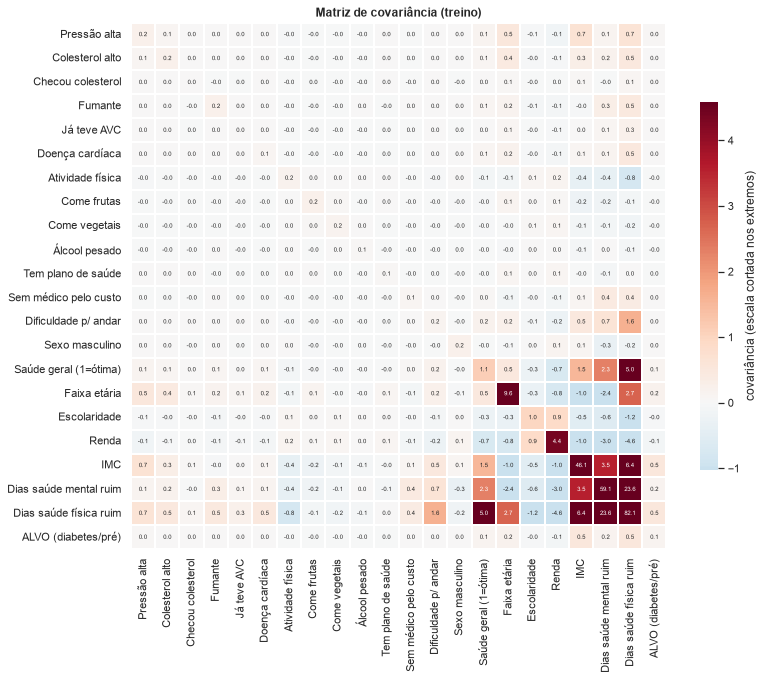

Variâncias (diagonal), da maior para a menor:


,Dias saúde física ruim,Dias saúde mental ruim,IMC,Faixa etária,Renda,Saúde geral (1=ótima),Escolaridade,Fumante,Pressão alta,Colesterol alto,Sexo masculino,Come frutas,Atividade física,Come vegetais,Dificuldade p/ andar,ALVO (diabetes/pré),Doença cardíaca,Sem médico pelo custo,Álcool pesado,Tem plano de saúde,Já teve AVC,Checou colesterol
variância,82.071,59.129,46.132,9.578,4.384,1.135,0.987,0.249,0.248,0.247,0.246,0.237,0.196,0.163,0.152,0.143,0.093,0.084,0.057,0.051,0.043,0.038


In [4]:
cov = train[[*features, BINARY_TARGET]].cov()

fig, ax = plt.subplots(figsize=(12, 9.5))
sns.heatmap(
    cov.rename(index=DESCRICAO, columns=DESCRICAO),
    cmap="RdBu_r",
    center=0,
    robust=True,
    annot=True,
    fmt=".1f",
    annot_kws={"fontsize": 6},
    linewidths=0.3,
    cbar_kws={"shrink": 0.7, "label": "covariância (escala cortada nos extremos)"},
    ax=ax,
)
ax.set(title="Matriz de covariância (treino)")
plt.show()

print("Variâncias (diagonal), da maior para a menor:")
pd.Series(np.diag(cov), index=cov.index).rename(index=DESCRICAO).sort_values(ascending=False).round(
    3
).to_frame("variância").T

### 2.4 O problema da covariância: ela depende da unidade

A matriz acima é difícil de ler: os maiores valores envolvem **dias de saúde
ruim** (0 a 30) e **IMC**, simplesmente porque essas variáveis têm números
grandes, e não porque têm relações mais fortes.

Teste simples: medimos "dias de saúde física ruim" em **semanas** (dividindo por 7).
A informação é exatamente a mesma, mas a covariância muda. A correlação, que
veremos a seguir, não muda.

In [5]:
dias = train["PhysHlth"]
semanas = dias / 7

pd.DataFrame(
    {
        "covariância com o alvo": [dias.cov(alvo), semanas.cov(alvo)],
        "correlação com o alvo": [dias.corr(alvo), semanas.corr(alvo)],
    },
    index=["PhysHlth em dias", "PhysHlth em semanas"],
).style.format("{:.4f}")

,covariância com o alvo,correlação com o alvo
PhysHlth em dias,0.5456,0.1594
PhysHlth em semanas,0.0779,0.1594


📌 **O que observamos**

- A covariância IMC × alvo é **positiva**: quem tem IMC acima da média tende a ter
  diabetes/pré-diabetes com mais frequência. A conta manual bate com o pandas.
- O **sinal** da covariância é informativo, mas o **tamanho** não: ele mistura a
  força da relação com a escala das variáveis. Mudar de dias para semanas dividiu
  a covariância por 7 sem mudar nada na informação.
- Por isso a covariância **não foi usada diretamente para comparar ou selecionar
  variáveis**. Ela é o ingrediente da correlação e aparece "por dentro" de
  métodos como PCA e regressão.

## 3. Coeficientes de correlação: Pearson, Spearman e Kendall

Um **coeficiente de correlação** resume em um número entre −1 e +1 a força e a
direção da associação entre duas variáveis. Os três mais usados diferem no
**tipo de relação** que detectam:

| Coeficiente | Símbolo | Mede relação... | Usa | Sensível a extremos? |
|---|---|---|---|---|
| **Pearson** | $r$ | **linear** | os valores | sim |
| **Spearman** | $\rho_s$ | **monotônica** (sempre sobe ou sempre desce) | os postos (rankings) | não |
| **Kendall** | $\tau$ | **monotônica** | a ordem de cada **par** de pessoas | não |

### 3.1 Pearson: a covariância padronizada

O coeficiente de Pearson divide a covariância pelos desvios-padrão, eliminando a
unidade:

$$
r_{XY} = \frac{\operatorname{cov}(X, Y)}{s_X \, s_Y}
= \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sqrt{\sum_i (x_i-\bar x)^2}\,\sqrt{\sum_i (y_i-\bar y)^2}}
\in [-1, 1]
$$

- $r = \pm 1$: os pontos caem exatamente sobre uma reta; $r = 0$: nenhuma relação **linear**.
- $r^2$ é a fração da variância de $Y$ explicada por uma reta em $X$ (seção 6.2).
- **Premissas** para interpretar e testar $r$: relação linear, ausência de extremos
  influentes e, para o teste clássico, normalidade aproximada (com amostras grandes
  essa exigência se relaxa pelo Teorema Central do Limite).

Em forma de matriz: $R = D^{-1}\,\Sigma\,D^{-1}$, onde $\Sigma$ é a matriz de
covariância e $D$ é a diagonal com os desvios-padrão. Conferimos que a conta
reproduz `DataFrame.corr()`.

In [6]:
desvios = np.sqrt(np.diag(cov))
D_inv = np.diag(1 / desvios)
corr_da_cov = pd.DataFrame(D_inv @ cov.to_numpy() @ D_inv, index=cov.index, columns=cov.columns)

pearson = train[[*features, BINARY_TARGET]].corr(method="pearson")
print(
    f"Maior diferença entre D⁻¹ΣD⁻¹ e df.corr(): {np.abs(corr_da_cov - pearson).to_numpy().max():.2e}"
)
print(
    f"IMC × alvo: cov = {cov.loc['BMI', BINARY_TARGET]:.4f}  →  r = {pearson.loc['BMI', BINARY_TARGET]:.4f}"
)

Maior diferença entre D⁻¹ΣD⁻¹ e df.corr(): 1.34e-14
IMC × alvo: cov = 0.5423  →  r = 0.2113


### 3.2 Spearman: Pearson aplicado aos postos

O Spearman substitui cada valor pela sua **posição** na ordenação (o menor vira 1,
o segundo vira 2, ...; empates recebem a posição média) e calcula o Pearson sobre
essas posições:

$$
\rho_s = r\big(\operatorname{posto}(X),\, \operatorname{posto}(Y)\big)
\qquad\text{(sem empates: } \rho_s = 1 - \tfrac{6\sum d_i^2}{n(n^2-1)}\text{)}
$$

Como só a **ordem** importa, $\rho_s = 1$ sempre que $Y$ cresce com $X$, mesmo que
a curva não seja uma reta, e um IMC de 98 pesa o mesmo que um de 50 (os dois são
apenas "os maiores"). Conferimos a definição:

In [7]:
postos = train[[*features, BINARY_TARGET]].rank()  # empates recebem o posto médio
spearman_manual = postos.corr(method="pearson")
spearman = train[[*features, BINARY_TARGET]].corr(method="spearman")
print(
    f"Maior diferença entre Pearson(postos) e corr(method='spearman'): {np.abs(spearman_manual - spearman).to_numpy().max():.2e}"
)

Maior diferença entre Pearson(postos) e corr(method='spearman'): 1.58e-14


### 3.3 Kendall: pares concordantes e discordantes

O Kendall olha **todos os pares de pessoas** $(i, j)$ e pergunta: a pessoa com
maior $X$ também tem maior $Y$?

- **concordante** ($C$): sim, a ordem em $X$ e em $Y$ é a mesma;
- **discordante** ($D$): a ordem se inverte;
- **empatado**: mesmo valor em $X$ ou em $Y$ (comum aqui: as variáveis binárias e
  ordinais têm muitos empates).

$$
\tau_a = \frac{C - D}{\binom{n}{2}}
\qquad\qquad
\tau_b = \frac{C - D}{\sqrt{(n_0 - n_X)(n_0 - n_Y)}}
$$

onde $n_0 = \binom{n}{2}$ é o total de pares e $n_X$, $n_Y$ são os pares empatados
em $X$ e em $Y$. O $\tau_b$ (padrão do `scipy` e do pandas) corrige os empates.

**Interpretação direta:** $\tau = 0{,}2$ significa que, entre os pares sem empate,
há 20 pontos percentuais a mais de pares concordantes que discordantes.

Contamos os pares "na mão" numa amostra de 400 pessoas (79.800 pares) e
conferimos com o `scipy`.

In [8]:
mini = train.sample(400, random_state=SEED)
x_k, y_k = mini["GenHlth"].to_numpy(), mini[BINARY_TARGET].to_numpy()

i, j = np.triu_indices(len(mini), k=1)  # todos os pares i < j
sinal = np.sign(x_k[i] - x_k[j]) * np.sign(y_k[i] - y_k[j])
C, D = (sinal > 0).sum(), (sinal < 0).sum()
n0 = len(i)
empates_x, empates_y = (x_k[i] == x_k[j]).sum(), (y_k[i] == y_k[j]).sum()

tau_a = (C - D) / n0
tau_b = (C - D) / np.sqrt((n0 - empates_x) * (n0 - empates_y))

pd.DataFrame(
    {
        "valor": [
            n0,
            C,
            D,
            empates_x,
            empates_y,
            tau_a,
            tau_b,
            stats.kendalltau(x_k, y_k).statistic,
        ],
    },
    index=[
        "pares (n₀)",
        "concordantes (C)",
        "discordantes (D)",
        "empatados em X (saúde geral)",
        "empatados em Y (alvo)",
        "τₐ (manual)",
        "τ_b (manual)",
        "τ_b (scipy)",
    ],
).style.format("{:,.4f}")

,valor
pares (n₀),"79,800.0000"
concordantes (C),"13,466.0000"
discordantes (D),"4,812.0000"
empatados em X (saúde geral),"20,676.0000"
empatados em Y (alvo),"56,441.0000"
τₐ (manual),0.1084
τ_b (manual),0.2329
τ_b (scipy),0.2329


### 3.4 Os três lado a lado em situações controladas

Para ver **o que cada coeficiente capta**, simulamos quatro cenários com 500 pontos:

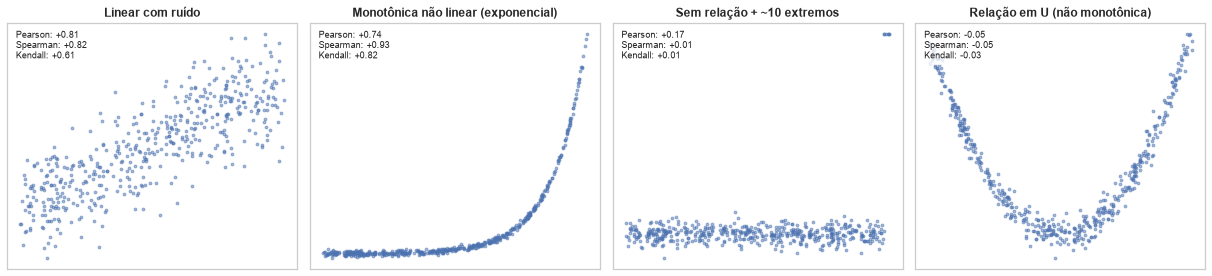

,Pearson,Spearman,Kendall
cenário,,,
Linear com ruído,+0.810,+0.821,+0.612
Monotônica não linear (exponencial),+0.743,+0.931,+0.816
Sem relação + ~10 extremos,+0.174,+0.013,+0.008
Relação em U (não monotônica),-0.053,-0.045,-0.034


In [9]:
rng = np.random.default_rng(SEED)
x_sim = rng.uniform(0, 1, 500)
sem_relacao = rng.normal(0, 1, 500)
cenarios = {
    "Linear com ruído": 2 * x_sim + rng.normal(0, 0.4, 500),
    "Monotônica não linear (exponencial)": np.exp(8 * x_sim) + rng.normal(0, 20, 500),
    "Sem relação + ~10 extremos": np.where(x_sim > 0.98, 30, sem_relacao),
    "Relação em U (não monotônica)": (x_sim - 0.5) ** 2 + rng.normal(0, 0.01, 500),
}

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
linhas = []
for ax, (nome, y_sim) in zip(axes, cenarios.items(), strict=True):
    coef = {
        "Pearson": stats.pearsonr(x_sim, y_sim).statistic,
        "Spearman": stats.spearmanr(x_sim, y_sim).statistic,
        "Kendall": stats.kendalltau(x_sim, y_sim).statistic,
    }
    linhas.append({"cenário": nome, **coef})
    ax.scatter(x_sim, y_sim, s=8, alpha=0.5, color="#4C72B0")
    ax.set(title=nome, xticks=[], yticks=[])
    ax.text(
        0.03,
        0.97,
        "\n".join(f"{k}: {v:+.2f}" for k, v in coef.items()),
        transform=ax.transAxes,
        va="top",
        fontsize=9,
        bbox={"facecolor": "white", "alpha": 0.8, "edgecolor": "none"},
    )
plt.tight_layout()
plt.show()
pd.DataFrame(linhas).set_index("cenário").style.format("{:+.3f}")

### 3.5 Os três coeficientes aplicados às 21 variáveis

,tipo,Pearson,Spearman,Kendall,Kendall / Spearman
Saúde geral (1=ótima),ordinal,+0.283,+0.280,+0.255,0.91
Pressão alta,binária,+0.260,+0.260,+0.260,1.00
IMC,contínua,+0.211,+0.225,+0.189,0.84
Dificuldade p/ andar,binária,+0.208,+0.208,+0.208,1.00
Colesterol alto,binária,+0.203,+0.203,+0.203,1.00
Faixa etária,ordinal,+0.187,+0.185,+0.158,0.85
Doença cardíaca,binária,+0.169,+0.169,+0.169,1.00
Renda,ordinal,-0.148,-0.147,-0.129,0.88
Dias saúde física ruim,contínua,+0.159,+0.140,+0.128,0.91
Atividade física,binária,-0.105,-0.105,-0.105,1.00


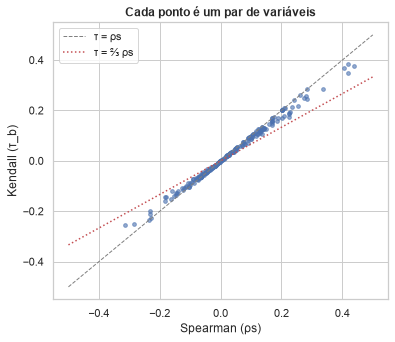

In [10]:
kendall = train[[*features, BINARY_TARGET]].corr(method="kendall")
tres = pd.DataFrame(
    {
        "tipo": pd.Series(TIPO),
        "Pearson": pearson.loc[features, BINARY_TARGET],
        "Spearman": spearman.loc[features, BINARY_TARGET],
        "Kendall": kendall.loc[features, BINARY_TARGET],
    }
)
tres["Kendall / Spearman"] = tres["Kendall"] / tres["Spearman"]
tres = tres.reindex(tres["Spearman"].abs().sort_values(ascending=False).index)

display(
    tres.rename(index=DESCRICAO)
    .style.format(
        {
            "Pearson": "{:+.3f}",
            "Spearman": "{:+.3f}",
            "Kendall": "{:+.3f}",
            "Kendall / Spearman": "{:.2f}",
        }
    )
    .background_gradient(
        subset=["Pearson", "Spearman", "Kendall"], cmap="RdBu_r", vmin=-0.35, vmax=0.35
    )
)

# Todos os pares de variáveis (não só com o alvo): Kendall contra Spearman.
triangulo = ~np.triu(np.ones_like(spearman, dtype=bool))
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    spearman.where(triangulo).stack(),
    kendall.where(triangulo).stack(),
    s=14,
    alpha=0.6,
    color="#4C72B0",
)
ax.plot([-0.5, 0.5], [-0.5, 0.5], ls="--", color="gray", lw=1, label="τ = ρs")
ax.plot([-0.5, 0.5], [-1 / 3, 1 / 3], ls=":", color="#C44E52", lw=1.5, label="τ = ⅔ ρs")
ax.set(xlabel="Spearman (ρs)", ylabel="Kendall (τ_b)", title="Cada ponto é um par de variáveis")
ax.legend()
plt.show()

### 3.6 Pearson × Spearman: onde eles discordam?

Se as duas medidas dão valores parecidos, a relação é aproximadamente linear. Se
diferem, há assimetria, extremos ou relação não linear.

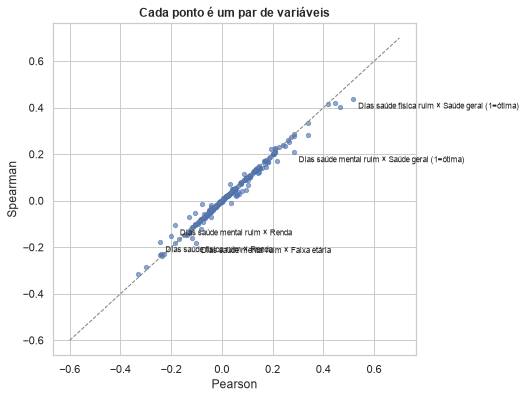

pearson  spearman  diferença
Dias saúde mental ruim Renda                   -0.185    -0.106      0.080
                       Faixa etária            -0.103    -0.182     -0.079
Dias saúde física ruim Saúde geral (1=ótima)    0.517     0.439     -0.078
Dias saúde mental ruim Saúde geral (1=ótima)    0.283     0.209     -0.074
Dias saúde física ruim Renda                   -0.243    -0.178      0.064
Dias saúde mental ruim Escolaridade            -0.077    -0.013      0.064
Dias saúde física ruim Dificuldade p/ andar     0.467     0.404     -0.063
                       Escolaridade            -0.128    -0.072      0.056

In [11]:
mascara = np.triu(np.ones_like(pearson, dtype=bool))
comparacao = pd.DataFrame(
    {
        "pearson": pearson.where(~mascara).stack(),
        "spearman": spearman.where(~mascara).stack(),
    }
)
comparacao["diferença"] = comparacao["spearman"] - comparacao["pearson"]

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(comparacao["pearson"], comparacao["spearman"], s=18, alpha=0.6, color="#4C72B0")
ax.plot([-0.6, 0.7], [-0.6, 0.7], ls="--", color="gray", lw=1)
for (a, b), linha in comparacao.reindex(comparacao["diferença"].abs().nlargest(5).index).iterrows():
    ax.annotate(
        f"{DESCRICAO[a]} × {DESCRICAO[b]}",
        (linha["pearson"], linha["spearman"]),
        fontsize=8,
        xytext=(5, -10),
        textcoords="offset points",
    )
ax.set(xlabel="Pearson", ylabel="Spearman", title="Cada ponto é um par de variáveis")
plt.show()

comparacao.reindex(comparacao["diferença"].abs().nlargest(8).index).rename(index=DESCRICAO).round(3)

### 3.7 Qual coeficiente usar para cada tipo de variável

| Par de variáveis | Medida recomendada | Observação |
|---|---|---|
| contínua × contínua, relação linear | **Pearson** | sensível a extremos |
| ordinal × qualquer | **Spearman** ou **Kendall** | só a ordem importa |
| binária × binária | **phi (φ)** | é o Pearson calculado em variáveis 0/1 |
| binária × contínua | **ponto-bisserial** | também é o Pearson com uma variável 0/1 |
| amostra pequena ou muitos empates | **Kendall** | distribuição amostral mais bem comportada |

Como a base mistura os três tipos de variável, a medida principal deste projeto é o
**Spearman**: funciona para ordinais (idade, renda, saúde geral), não é afetado
pelos extremos do IMC e, nos binários, praticamente coincide com o phi. O Kendall
dá as **mesmas conclusões** (mesma ordem) e serve como confirmação.

### 3.8 Mapa de correlações (Spearman)

Ordenamos as variáveis por **agrupamento hierárquico**: variáveis que se
correlacionam entre si ficam vizinhas, formando "blocos" no mapa.

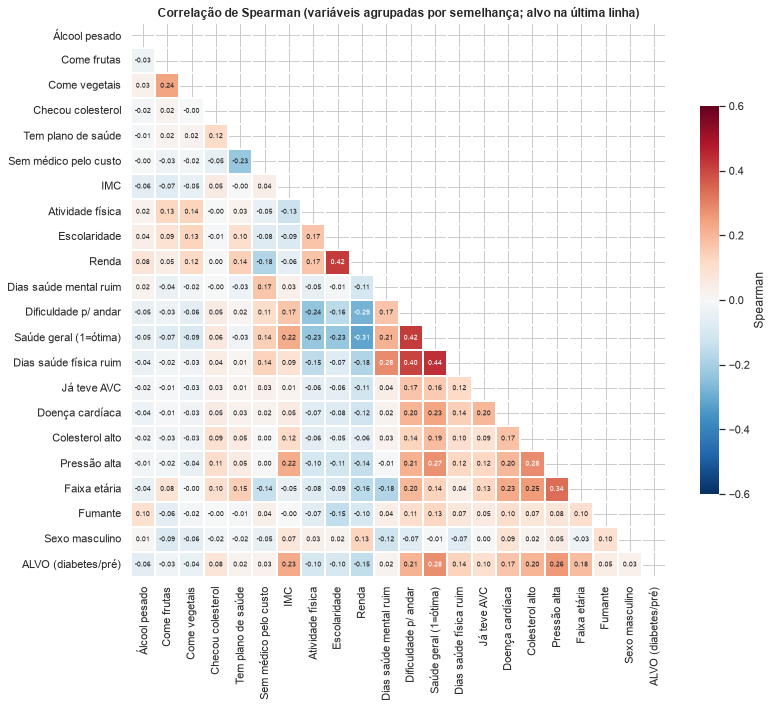

In [12]:
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.spatial.distance import squareform

corr_feat = spearman.loc[features, features]
distancia = squareform(1 - corr_feat.abs().to_numpy(), checks=False)  # 0 = muito correlacionadas
ordem = [features[i] for i in leaves_list(linkage(distancia, method="average"))] + [BINARY_TARGET]

mapa = spearman.loc[ordem, ordem].rename(index=DESCRICAO, columns=DESCRICAO)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(
    mapa,
    mask=np.triu(np.ones_like(mapa, dtype=bool)),
    cmap="RdBu_r",
    center=0,
    vmin=-0.6,
    vmax=0.6,
    annot=True,
    fmt=".2f",
    annot_kws={"fontsize": 7},
    linewidths=0.3,
    cbar_kws={"shrink": 0.7, "label": "Spearman"},
    ax=ax,
)
ax.set(title="Correlação de Spearman (variáveis agrupadas por semelhança; alvo na última linha)")
plt.show()

📌 **O que observamos**

- A conta $D^{-1}\Sigma D^{-1}$ reproduz exatamente o `df.corr()`: correlação **é**
  a covariância sem unidade, e por isso dá para comparar pares diferentes. O mesmo
  vale para o Spearman (Pearson dos postos) e para o Kendall (contagem de pares).
- **Cenários simulados:**
  - na relação **linear**, os três detectam a associação (o Kendall sempre dá um
    número menor, porque está em outra escala);
  - na **exponencial**, Spearman e Kendall ficam mais altos que o Pearson: a relação
    é perfeitamente monotônica, mas não é uma reta;
  - com **~10 extremos** em 500 pontos, o Pearson "inventa" uma correlação que não
    existe; Spearman e Kendall quase não se movem;
  - na relação **em U**, os três ficam perto de zero apesar de a relação ser forte.
    Nenhum coeficiente de correlação capta relações não monotônicas; para isso
    existe a informação mútua (seção 8.2).
- **Nos dados reais**, Pearson, Spearman e Kendall ordenam as variáveis
  praticamente do mesmo jeito.
- **Com duas variáveis binárias os três coeficientes são idênticos** (todos viram o
  phi): por isso pressão alta, colesterol etc. têm o mesmo valor nas três colunas.
  Nas ordinais e contínuas, o Kendall fica entre 84% e 93% do Spearman.
- A regra prática $\tau \approx \tfrac{2}{3}\rho_s$ (linha pontilhada vermelha) vale
  para variáveis contínuas **sem empates**, como no cenário linear simulado
  (0,61 × 0,82). Aqui quase todos os pontos caem na diagonal $\tau = \rho_s$ porque a
  base é dominada por empates (variáveis binárias e escalas curtas). Moral: valores
  de coeficientes diferentes **não** são comparáveis entre si; compare sempre dentro
  do mesmo coeficiente.
- **Dias de saúde mental ruim:** Pearson 0,059 × Spearman 0,023. O Pearson é
  inflado pelos poucos que relatam 30 dias ruins (cauda longa).
- As maiores diferenças entre Pearson e Spearman envolvem **dias de saúde
  física/mental ruim**, muito assimétricos (a maioria responde 0). Isso confirma a
  escolha do Spearman.
- O agrupamento revela **blocos** de variáveis que medem coisas parecidas:
  *saúde debilitada* (saúde geral, dias de saúde física ruim, dificuldade de andar),
  *nível socioeconômico* (renda, escolaridade) e *cardiometabólico* (pressão,
  colesterol, doença cardíaca, idade).

## 4. Testes de hipótese para correlação

Um coeficiente calculado numa **amostra** é uma estimativa do coeficiente da
**população** (todos os adultos dos EUA). Mesmo que na população a correlação seja
zero, a amostra quase sempre dá um valor diferente de zero, só por acaso. O teste
de hipótese pergunta: *o valor observado é grande demais para ser só acaso?*

### 4.1 A estrutura de um teste

| Elemento | No teste de correlação |
|---|---|
| **Hipótese nula** $H_0$ | $\rho = 0$ (não há associação na população) |
| **Hipótese alternativa** $H_1$ | $\rho \ne 0$ (bilateral) |
| **Estatística de teste** | número calculado na amostra cuja distribuição sob $H_0$ é conhecida |
| **p-valor** | probabilidade de observar uma estatística tão extrema quanto a obtida **se $H_0$ fosse verdadeira** |
| **Nível de significância** $\alpha$ | limite para rejeitar $H_0$ (usamos 5%) |
| **Erro tipo I** | rejeitar $H_0$ verdadeira (probabilidade $\alpha$) |
| **Erro tipo II** | não rejeitar $H_0$ falsa (cai com o tamanho da amostra) |

> O p-valor **não** é a probabilidade de $H_0$ ser verdadeira, e um p-valor
> pequeno **não** indica uma relação forte. Ele mede só a incompatibilidade dos
> dados com "correlação exatamente zero".

### 4.2 Estatísticas de teste

**Pearson (e Spearman, por aproximação):** sob $H_0$,

$$
t = \frac{r\sqrt{n-2}}{\sqrt{1-r^2}} \;\sim\; t_{n-2}
\qquad\qquad p = 2\,P(T_{n-2} > |t|)
$$

**Kendall:** sob $H_0$ (sem empates), $\tau$ é aproximadamente normal com variância
conhecida:

$$
z = \frac{3\,\tau\,\sqrt{n(n-1)}}{\sqrt{2(2n+5)}} \;\sim\; N(0, 1)
$$

O `scipy` usa uma versão dessa fórmula corrigida para empates.

Fazemos a conta do teste t na mão para a relação **IMC × alvo** numa amostra de
200 pessoas (com a base inteira, o p-valor seria zero e não teria graça) e
conferimos com o `scipy`:

In [13]:
amostra_teste = train.sample(200, random_state=SEED)
x_t, y_t = amostra_teste["BMI"], amostra_teste[BINARY_TARGET]
n_t = len(amostra_teste)

linhas = []
for nome, r in [
    ("Pearson", stats.pearsonr(x_t, y_t).statistic),
    ("Spearman", stats.spearmanr(x_t, y_t).statistic),
]:
    t = r * np.sqrt(n_t - 2) / np.sqrt(1 - r**2)
    p_manual = 2 * stats.t.sf(abs(t), df=n_t - 2)
    p_scipy = (stats.pearsonr if nome == "Pearson" else stats.spearmanr)(x_t, y_t).pvalue
    linhas.append(
        {
            "coeficiente": nome,
            "valor": r,
            "estatística": t,
            "p (manual)": p_manual,
            "p (scipy)": p_scipy,
        }
    )

tau = stats.kendalltau(x_t, y_t)
z = 3 * tau.statistic * np.sqrt(n_t * (n_t - 1)) / np.sqrt(2 * (2 * n_t + 5))
linhas.append(
    {
        "coeficiente": "Kendall",
        "valor": tau.statistic,
        "estatística": z,
        "p (manual)": 2 * stats.norm.sf(abs(z)),
        "p (scipy)": tau.pvalue,
    }
)
pd.DataFrame(linhas).set_index("coeficiente").style.format(
    {"valor": "{:+.3f}", "estatística": "{:.3f}", "p (manual)": "{:.2e}", "p (scipy)": "{:.2e}"}
)

,valor,estatística,p (manual),p (scipy)
coeficiente,,,,
Pearson,+0.294,4.332,2.35e-05,2.35e-05
Spearman,+0.298,4.393,1.82e-05,1.82e-05
Kendall,+0.250,5.266,1.39e-07,2.62e-05


### 4.3 Teste de permutação: o p-valor sem fórmulas

O teste de permutação constrói a distribuição sob $H_0$ **simulando** $H_0$: se não
há relação entre X e Y, embaralhar Y não muda nada. Repetimos o embaralhamento
milhares de vezes, calculamos a correlação em cada um e vemos com que frequência
o acaso produz um valor tão extremo quanto o observado. Não exige normalidade
nem fórmulas.

Comparamos duas variáveis numa amostra de 300 pessoas: o **IMC** (associação
moderada) e os **dias de saúde mental ruim** (associação muito fraca).

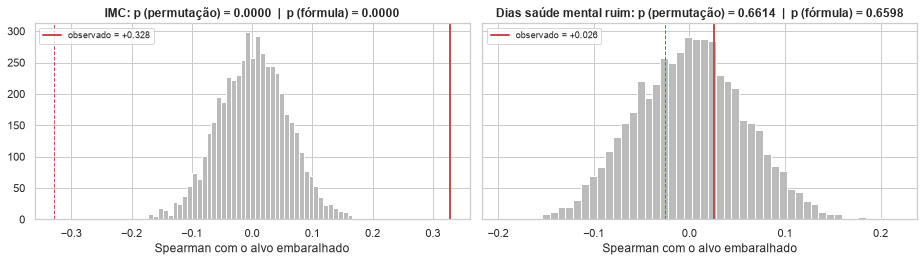

In [14]:
amostra_perm = train.sample(300, random_state=SEED)
y_postos = amostra_perm[BINARY_TARGET].rank().to_numpy()
N_PERMUTACOES = 5_000

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, col in zip(axes, ["BMI", "MentHlth"], strict=True):
    x_postos = amostra_perm[col].rank().to_numpy()
    observado = np.corrcoef(x_postos, y_postos)[0, 1]  # Spearman
    nulos = np.array(
        [np.corrcoef(x_postos, rng.permutation(y_postos))[0, 1] for _ in range(N_PERMUTACOES)]
    )
    p_perm = (np.abs(nulos) >= abs(observado)).mean()
    ax.hist(nulos, bins=50, color="#BBBBBB")
    ax.axvline(observado, color="#C44E52", lw=2, label=f"observado = {observado:+.3f}")
    ax.axvline(-observado, color="#C44E52", lw=1, ls="--")
    ax.set(
        title=f"{DESCRICAO[col]}: p (permutação) = {p_perm:.4f}  |  p (fórmula) = "
        f"{stats.spearmanr(amostra_perm[col], amostra_perm[BINARY_TARGET]).pvalue:.4f}",
        xlabel="Spearman com o alvo embaralhado",
    )
    ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

### 4.4 O tamanho da amostra decide a significância

O mesmo coeficiente pode ser "não significativo" com 100 pessoas e "altamente
significativo" com 100 mil. Repetimos o teste de Spearman em amostras de tamanhos
crescentes:

In [15]:
variaveis_teste = ["GenHlth", "Smoker", "Fruits", "MentHlth"]
tamanhos = [100, 1_000, 10_000, len(train)]

p_por_n = pd.DataFrame(
    {
        f"n = {n_amostra:,}": {
            DESCRICAO[col]: stats.spearmanr(sub[col], sub[BINARY_TARGET]).pvalue
            for col in variaveis_teste
            for sub in [train.sample(n_amostra, random_state=SEED)]
        }
        for n_amostra in tamanhos
    }
)
p_por_n.insert(
    0, "ρs (base inteira)", spearman.loc[variaveis_teste, BINARY_TARGET].set_axis(p_por_n.index)
)
p_por_n.style.format("{:.1e}").format({"ρs (base inteira)": "{:+.3f}"}).map(
    lambda v: "background-color: #C6E2C6" if v < 0.05 else "", subset=p_por_n.columns[1:]
)

,ρs (base inteira),n = 100,"n = 1,000","n = 10,000","n = 183,769"
Saúde geral (1=ótima),+0.280,0.010731,0.000000,0.000000,0.000000
Fumante,+0.047,0.037507,0.000488,0.000002,0.000000
Come frutas,-0.026,0.440775,0.335883,0.001046,0.000000
Dias saúde mental ruim,+0.023,0.772670,0.522828,0.103790,0.000000


### 4.5 Testando as 21 variáveis: o problema dos múltiplos testes

Fazer 21 testes a 5% aumenta a chance de pelo menos um falso positivo para
$1 - 0{,}95^{21} \approx 66\%$. Duas correções clássicas:

- **Bonferroni:** compara cada p-valor com $\alpha / m$ ($m$ = nº de testes). Simples e conservadora.
- **Holm:** ordena os p-valores e compara o $k$-ésimo menor com $\alpha / (m - k + 1)$.
  Controla o mesmo erro, com mais poder.

Aplicamos os três testes (Pearson, Spearman, Kendall) às 21 variáveis na base de
treino inteira e, para contraste, numa amostra de 1.000 pessoas.

In [16]:
def holm(p: pd.Series, alpha: float = 0.05) -> pd.Series:
    # Rejeita H0 para os p-valores aprovados pelo procedimento de Holm.
    ordenado = p.sort_values()
    limites = alpha / (len(p) - np.arange(len(p)))
    aprovados = np.minimum.accumulate(ordenado.to_numpy() <= limites)  # para no primeiro que falha
    return pd.Series(aprovados, index=ordenado.index).reindex(p.index)


TESTES = {"Pearson": stats.pearsonr, "Spearman": stats.spearmanr, "Kendall": stats.kendalltau}
resumo_testes = []
for rotulo, dados in [
    ("base inteira", train),
    ("amostra de 1.000", train.sample(1_000, random_state=SEED)),
]:
    for nome, teste in TESTES.items():
        p = pd.Series({col: teste(dados[col], dados[BINARY_TARGET]).pvalue for col in features})
        resumo_testes.append(
            {
                "dados": rotulo,
                "teste": nome,
                "p < 0,05 (sem correção)": (p < 0.05).sum(),
                "Bonferroni": (p < 0.05 / len(p)).sum(),
                "Holm": holm(p).sum(),
            }
        )
pd.DataFrame(resumo_testes).set_index(["dados", "teste"]).rename(
    columns=lambda c: f"variáveis significativas: {c}"
)

variáveis significativas: p < 0,05 (sem correção)  \
dados            teste                                                         
base inteira     Pearson                                                  21   
                 Spearman                                                 21   
                 Kendall                                                  21   
amostra de 1.000 Pearson                                                  16   
                 Spearman                                                 16   
                 Kendall                                                  16   

                           variáveis significativas: Bonferroni  \
dados            teste                                            
base inteira     Pearson                                     21   
                 Spearman                                    21   
                 Kendall                                     21   
amostra de 1.000 Pearson                                     12   
                 Spearman                                    11   
                 Kendall                                     11   

                           variáveis significativas: Holm  
dados            teste                                     
base inteira     Pearson                               21  
                 Spearman                              21  
                 Kendall                               21  
amostra de 1.000 Pearson                               14  
                 Spearman                              14  
                 Kendall                               14

📌 **O que observamos**

- A conta manual do teste t (Pearson e Spearman) bate com o `scipy`. No Kendall o
  z manual usa a fórmula sem empates; o `scipy` corrige os empates, que aqui são a
  maioria dos pares (alvo binário), por isso os dois p-valores diferem.
- **Teste de permutação:** com 300 pessoas, o IMC fica muito fora da distribuição
  do acaso (p ≈ 0), enquanto os dias de saúde mental ruim ficam no meio dela
  (p alto, não rejeitamos $H_0$). O p-valor por permutação é praticamente igual ao
  da fórmula: a aproximação t funciona bem mesmo com 300 pessoas.
- **Tamanho da amostra:** com 100 pessoas, até a saúde geral (ρs = 0,28) tem
  p ≈ 0,01. Frutas (ρs = −0,026) só fica "significativa" a partir de 10 mil pessoas,
  e os dias de saúde mental ruim (0,023), só na base inteira.
- **Múltiplos testes:** numa amostra de 1.000 pessoas, 16 variáveis passam sem
  correção, 14 com Holm e 11–12 com Bonferroni (o mais conservador). Na base
  inteira, **todas as 21** rejeitam $H_0$ nos três testes, mesmo após a correção.
- **Conclusão para a seleção:** com uma base deste tamanho, o teste de hipótese não
  separa variáveis úteis de inúteis; ele só confirma que nenhuma correlação é
  exatamente zero. A seleção precisa olhar o **tamanho do efeito** (o coeficiente e
  seu intervalo de confiança, seção 5) e o **efeito no modelo** (seções 8 e 9).

## 5. Estimação dos coeficientes de correlação

O teste responde "é zero ou não?". A **estimação** responde "quanto vale, e com que
precisão?". Ela tem duas partes:

- **estimativa pontual**: o valor calculado na amostra ($r$, $\rho_s$ ou $\tau$);
- **estimativa intervalar**: um **intervalo de confiança** (IC) que, em 95% das
  amostras possíveis, conteria o valor verdadeiro da população.

### 5.1 Distribuição amostral: quanto o coeficiente varia de amostra para amostra

Se repetíssemos a pesquisa muitas vezes, cada amostra daria um $r$ diferente. A
dispersão desses valores é o **erro padrão**. Simulamos isso sorteando 3.000
amostras de 500 pessoas e calculando o Pearson IMC × alvo em cada uma:

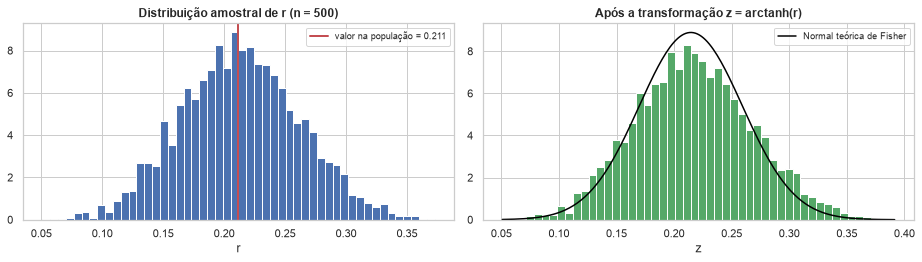

,simulado,teoria
média de r,0.2129,0.2113
erro padrão de r,0.0489,0.0428
assimetria de r,0.0476,—
erro padrão de z,0.0514,0.0449


In [17]:
N_SIM, N_POR_AMOSTRA = 3_000, 500
imc_arr, alvo_arr = train["BMI"].to_numpy(), train[BINARY_TARGET].to_numpy()
r_populacao = np.corrcoef(imc_arr, alvo_arr)[0, 1]  # tratamos o treino inteiro como "população"

indices = rng.integers(0, len(train), size=(N_SIM, N_POR_AMOSTRA))
xs, ys = imc_arr[indices], alvo_arr[indices]
xs_c, ys_c = xs - xs.mean(axis=1, keepdims=True), ys - ys.mean(axis=1, keepdims=True)
r_amostras = (xs_c * ys_c).sum(axis=1) / np.sqrt((xs_c**2).sum(axis=1) * (ys_c**2).sum(axis=1))
z_amostras = np.arctanh(r_amostras)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(r_amostras, bins=50, color="#4C72B0", density=True)
axes[0].axvline(r_populacao, color="#C44E52", lw=2, label=f"valor na população = {r_populacao:.3f}")
axes[0].set(title="Distribuição amostral de r (n = 500)", xlabel="r")
axes[0].legend(fontsize=9)
axes[1].hist(z_amostras, bins=50, color="#55A868", density=True)
grade = np.linspace(z_amostras.min(), z_amostras.max(), 200)
axes[1].plot(
    grade,
    stats.norm.pdf(grade, np.arctanh(r_populacao), 1 / np.sqrt(N_POR_AMOSTRA - 3)),
    color="black",
    lw=1.5,
    label="Normal teórica de Fisher",
)
axes[1].set(title="Após a transformação z = arctanh(r)", xlabel="z")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

pd.DataFrame(
    {
        "simulado": [r_amostras.mean(), r_amostras.std(), stats.skew(r_amostras), z_amostras.std()],
        "teoria": [
            r_populacao,
            (1 - r_populacao**2) / np.sqrt(N_POR_AMOSTRA - 1),
            np.nan,
            1 / np.sqrt(N_POR_AMOSTRA - 3),
        ],
    },
    index=["média de r", "erro padrão de r", "assimetria de r", "erro padrão de z"],
).style.format("{:.4f}", na_rep="—")

O estimador $r$ é **aproximadamente não viesado** (a média das simulações fica no
valor da população) e seu erro padrão é

$$
\operatorname{EP}(r) \approx \frac{1 - \rho^2}{\sqrt{n - 1}},
$$

que **cai com $\sqrt{n}$**: quadruplicar a amostra reduz o erro pela metade.

> Essa fórmula (e a de Fisher, abaixo) supõe que $X$ e $Y$ têm distribuição
> **normal bivariada**. Aqui o alvo é 0/1 e o IMC é assimétrico, por isso o erro
> padrão simulado fica cerca de 14% **acima** do teórico. É um bom motivo para
> conferir os intervalos com bootstrap (seção 5.3).

### 5.2 Intervalo de confiança pela transformação de Fisher

A distribuição de $r$ é assimétrica perto de ±1 (o valor não pode passar de 1).
Fisher mostrou que $z = \operatorname{arctanh}(r)$ é aproximadamente normal com
erro padrão $1/\sqrt{n-3}$, que **não depende de $\rho$**. O IC é construído em $z$ e
convertido de volta:

$$
\text{IC}_{95\%}(\rho) = \tanh\!\left(\operatorname{arctanh}(r) \pm \frac{1{,}96}{\sqrt{n-3}}\right)
$$

Para Spearman e Kendall usam-se as variâncias aproximadas de Fieller:
$\operatorname{EP}(z_{\rho_s}) \approx \sqrt{1{,}06/(n-3)}$ e
$\operatorname{EP}(z_{\tau}) \approx \sqrt{0{,}437/(n-4)}$.

Aplicamos às 21 variáveis na base de treino inteira:

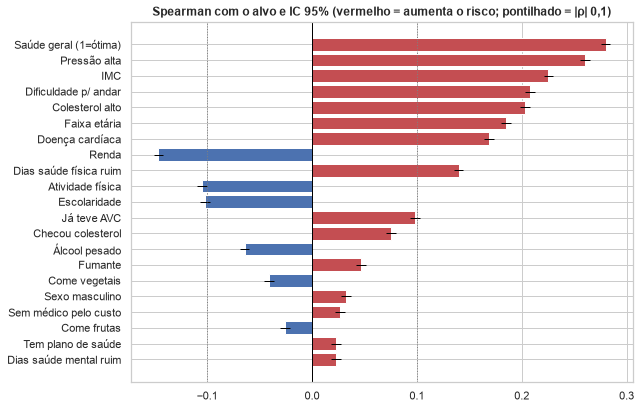

,tipo,spearman,IC 95% (inf),IC 95% (sup)
variável,,,,
Saúde geral (1=ótima),ordinal,+0.280,+0.276,+0.284
Pressão alta,binária,+0.260,+0.256,+0.265
IMC,contínua,+0.225,+0.221,+0.230
Dificuldade p/ andar,binária,+0.208,+0.203,+0.212
Colesterol alto,binária,+0.203,+0.198,+0.207
Faixa etária,ordinal,+0.185,+0.180,+0.189
Doença cardíaca,binária,+0.169,+0.164,+0.173
Renda,ordinal,-0.147,-0.151,-0.142
Dias saúde física ruim,contínua,+0.140,+0.135,+0.144


In [18]:
def ic_fisher(valor: float, n: int, metodo: str, nivel: float = 0.95) -> tuple[float, float]:
    # IC pela transformação de Fisher (variâncias de Fieller para Spearman e Kendall).
    ep = {
        "Pearson": 1 / np.sqrt(n - 3),
        "Spearman": np.sqrt(1.06 / (n - 3)),
        "Kendall": np.sqrt(0.437 / (n - 4)),
    }[metodo]
    z_crit = stats.norm.ppf(0.5 + nivel / 2)
    return np.tanh(np.arctanh(valor) - z_crit * ep), np.tanh(np.arctanh(valor) + z_crit * ep)


n = len(train)
linhas = []
for col in features:
    rho = spearman.loc[col, BINARY_TARGET]
    inf, sup = ic_fisher(rho, n, "Spearman")
    linhas.append(
        {
            "variável": DESCRICAO[col],
            "tipo": TIPO[col],
            "spearman": rho,
            "IC 95% (inf)": inf,
            "IC 95% (sup)": sup,
        }
    )
com_alvo = (
    pd.DataFrame(linhas).set_index("variável").sort_values("spearman", key=abs, ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 6.5))
dados = com_alvo.iloc[::-1]
ax.barh(
    dados.index,
    dados["spearman"],
    color=["#C44E52" if v > 0 else "#4C72B0" for v in dados["spearman"]],
)
ax.errorbar(
    dados["spearman"],
    dados.index,
    xerr=[dados["spearman"] - dados["IC 95% (inf)"], dados["IC 95% (sup)"] - dados["spearman"]],
    fmt="none",
    ecolor="black",
    lw=1,
)
ax.axvline(0, color="black", lw=1)
for limite in (0.1, -0.1):
    ax.axvline(limite, ls=":", color="gray", lw=1)
ax.set(
    title="Spearman com o alvo e IC 95% (vermelho = aumenta o risco; pontilhado = |ρ| 0,1)",
    xlabel="",
)
plt.show()

com_alvo.style.format(
    {"spearman": "{:+.3f}", "IC 95% (inf)": "{:+.3f}", "IC 95% (sup)": "{:+.3f}"}
).background_gradient(subset=["spearman"], cmap="RdBu_r", vmin=-0.35, vmax=0.35)

### 5.3 Intervalo de confiança por bootstrap

O **bootstrap** estima a distribuição amostral sem fórmulas: sorteamos, **com
reposição**, milhares de amostras do mesmo tamanho dos dados, recalculamos o
coeficiente em cada uma e usamos os percentis 2,5% e 97,5% como IC. Funciona para
qualquer coeficiente, inclusive quando não há fórmula confiável.

Comparamos os ICs de Fisher e de bootstrap numa amostra de 2.000 pessoas (na base
inteira os intervalos ficam estreitos demais para ver diferença):

In [19]:
amostra_boot = train.sample(2_000, random_state=SEED)
N_BOOT = 1_000
indices_boot = rng.integers(0, len(amostra_boot), size=(N_BOOT, len(amostra_boot)))

linhas = []
for col in ["GenHlth", "BMI", "Smoker", "MentHlth"]:
    x_b, y_b = amostra_boot[col].to_numpy(), amostra_boot[BINARY_TARGET].to_numpy()
    for nome, funcao in TESTES.items():
        valor = funcao(x_b, y_b).statistic
        reamostras = np.array([funcao(x_b[idx], y_b[idx]).statistic for idx in indices_boot])
        f_inf, f_sup = ic_fisher(valor, len(x_b), nome)
        linhas.append(
            {
                "variável": DESCRICAO[col],
                "coeficiente": nome,
                "estimativa": valor,
                "EP (bootstrap)": reamostras.std(),
                "IC Fisher": f"[{f_inf:+.3f}, {f_sup:+.3f}]",
                "IC bootstrap": f"[{np.percentile(reamostras, 2.5):+.3f}, {np.percentile(reamostras, 97.5):+.3f}]",
                "contém 0?": "sim" if f_inf <= 0 <= f_sup else "não",
            }
        )
pd.DataFrame(linhas).set_index(["variável", "coeficiente"]).style.format(
    {"estimativa": "{:+.3f}", "EP (bootstrap)": "{:.4f}"}
)

📌 **O que observamos**

- **A simulação confirma o essencial da teoria:** a média dos $r$ simulados
  coincide com o valor da população (estimador sem viés relevante) e, após a
  transformação de Fisher, a distribuição fica simétrica e com forma normal. O erro
  padrão real, porém, é ~14% maior que o da fórmula (0,049 × 0,043), porque os dados
  não são normais: os ICs de Fisher ficam um pouco **otimistas** (estreitos demais).
- **Na base inteira, os ICs são estreitos** (cerca de ±0,005): os coeficientes são
  estimados com muita precisão. Por isso a diferença entre, por exemplo, saúde geral
  (0,28) e pressão alta (0,26) é real, e não ruído de amostragem: os intervalos não
  se sobrepõem.
- **Fisher × bootstrap:** para Spearman os intervalos são praticamente iguais; para
  Pearson o bootstrap é um pouco mais largo (efeito da não normalidade). Para
  Kendall, a fórmula de Fieller **subestima** a incerteza quando há muitos empates:
  no fumo (binária), o IC de Fisher tem metade da largura do bootstrap. Com dados
  cheios de empates, ou sem fórmula confiável, **o bootstrap é a opção segura**.
- **O IC substitui o p-valor com vantagem:** com 2.000 pessoas, os ICs de Spearman
  e Kendall para saúde mental contêm o zero (não dá para afirmar associação),
  enquanto os de saúde geral e IMC ficam longe dele. O Pearson de saúde mental
  exclui o zero só por causa da cauda longa, outro sinal de que ele é a medida
  errada para essa variável. E o IC diz **quanto** vale a associação, não só se ela existe.
- As associações mais fortes (|ρ| ≳ 0,2) são **saúde geral, pressão alta, IMC,
  dificuldade de andar e colesterol alto**, seguidas da idade (0,19). Renda,
  atividade física e escolaridade têm sinal **negativo** (protetoras). Nenhuma
  variável passa de 0,28: sozinha, nenhuma explica bem o alvo.

## 6. Modelos estatísticos e estimação dos coeficientes

### 6.1 O que é um modelo estatístico

Correlações olham **pares** de variáveis. Um **modelo estatístico** descreve o alvo
em função de **várias variáveis ao mesmo tempo**, com uma parte sistemática e uma
parte aleatória:

$$
\underbrace{Y}_{\text{resposta}} = \underbrace{f(X;\,\beta)}_{\text{parte sistemática}} + \underbrace{\varepsilon}_{\text{parte aleatória}}
$$

Os **coeficientes** $\beta$ são desconhecidos e precisam ser **estimados** a partir
dos dados. Junto com cada estimativa vem um erro padrão, um IC e um teste, como
nas correlações.

| | Modelo estatístico (ex.: regressão logística) | Modelo de *machine learning* (ex.: o boosting do projeto) |
|---|---|---|
| Objetivo principal | **inferência**: quanto cada variável contribui, com incerteza | **predição**: acertar novos casos |
| Forma | fixada pelo analista (ex.: linear no logit) | aprendida dos dados (interações, não linearidades) |
| Saída | coeficientes, IC, p-valores | probabilidades; importância por permutação |
| Avaliação | ajuste, testes, AIC/BIC | validação cruzada, PR-AUC |

Os dois se complementam: o modelo estatístico **explica**; o de ML **prevê**.

### 6.2 Regressão linear simples: a ponte entre correlação e modelo

O modelo $Y = \beta_0 + \beta_1 X + \varepsilon$ é estimado por **mínimos quadrados
ordinários** (MQO), que escolhe a reta que minimiza $\sum (y_i - \hat y_i)^2$. As
estimativas têm forma fechada e estão ligadas à correlação:

$$
\hat\beta_1 = \frac{\operatorname{cov}(X,Y)}{\operatorname{var}(X)} = r\,\frac{s_Y}{s_X}
\qquad
\hat\beta_0 = \bar y - \hat\beta_1 \bar x
\qquad
R^2 = r^2
$$

Em notação matricial, $\hat\beta = (X^\top X)^{-1} X^\top y$, com erro padrão
$\operatorname{EP}(\hat\beta) = \sqrt{\hat\sigma^2\,\operatorname{diag}\big((X^\top X)^{-1}\big)}$.

Ajustamos **dias de saúde física ruim** em função da **saúde geral** (as duas
variáveis mais correlacionadas da base) e conferimos as três identidades:

In [20]:
x_lin, y_lin = train["GenHlth"].to_numpy(float), train["PhysHlth"].to_numpy(float)
n_lin = len(x_lin)

# Forma matricial: β = (XᵀX)⁻¹ Xᵀ y
A_lin = np.column_stack([np.ones(n_lin), x_lin])
beta_lin = np.linalg.solve(A_lin.T @ A_lin, A_lin.T @ y_lin)
residuos = y_lin - A_lin @ beta_lin
sigma2 = residuos @ residuos / (n_lin - 2)  # variância dos resíduos
ep_lin = np.sqrt(sigma2 * np.diag(np.linalg.inv(A_lin.T @ A_lin)))
r_lin = np.corrcoef(x_lin, y_lin)[0, 1]
r2_lin = 1 - residuos @ residuos / ((y_lin - y_lin.mean()) @ (y_lin - y_lin.mean()))
t_beta = beta_lin[1] / ep_lin[1]
t_r = r_lin * np.sqrt(n_lin - 2) / np.sqrt(1 - r_lin**2)
ref = stats.linregress(x_lin, y_lin)

pd.DataFrame(
    {
        "pela fórmula": [
            beta_lin[0],
            beta_lin[1],
            r_lin * y_lin.std() / x_lin.std(),
            ep_lin[1],
            r2_lin,
            r_lin**2,
            t_beta,
            t_r,
        ],
        "scipy.linregress": [
            ref.intercept,
            ref.slope,
            ref.slope,
            ref.stderr,
            ref.rvalue**2,
            ref.rvalue**2,
            ref.slope / ref.stderr,
            ref.slope / ref.stderr,
        ],
    },
    index=[
        "β₀ (intercepto)",
        "β₁ = (XᵀX)⁻¹Xᵀy",
        "β₁ = r · s_Y / s_X",
        "EP(β₁)",
        "R² do modelo",
        "r² (correlação ao quadrado)",
        "t do coeficiente β₁",
        "t do teste de correlação",
    ],
).style.format("{:.4f}")

,pela fórmula,scipy.linregress
β₀ (intercepto),-6.7622,-6.7622
β₁ = (XᵀX)⁻¹Xᵀy,4.4010,4.4010
β₁ = r · s_Y / s_X,4.4010,4.4010
EP(β₁),0.0170,0.0170
R² do modelo,0.2678,0.2678
r² (correlação ao quadrado),0.2678,0.2678
t do coeficiente β₁,259.2304,259.2304
t do teste de correlação,259.2304,259.2304


Cada nível a mais na escala de saúde geral (1 = excelente … 5 = ruim) está associado
a ~$\hat\beta_1$ dias a mais de saúde física ruim por mês. Note que **o teste t de
$\beta_1 = 0$ é idêntico ao teste t de $\rho = 0$** da seção 4: na regressão simples,
testar a inclinação é testar a correlação.

### 6.3 Regressão logística: o modelo adequado para um alvo binário

O alvo é 0/1, então uma reta não serve (preveria probabilidades negativas ou acima
de 1). A **regressão logística** modela o **logit** (log da chance) como linear:

$$
\log\frac{p_i}{1-p_i} = \beta_0 + \beta_1 x_{i1} + \dots + \beta_k x_{ik} = x_i^\top\beta,
\qquad
p_i = P(Y_i = 1 \mid x_i) = \frac{1}{1+e^{-x_i^\top\beta}}
$$

**Interpretação:** $e^{\beta_j}$ é a **razão de chances** (*odds ratio*, OR): quanto a
chance de ter diabetes/pré-diabetes é multiplicada quando $x_j$ aumenta 1 unidade,
**mantendo as demais variáveis constantes**.

### 6.4 Estimação por máxima verossimilhança

Não há fórmula fechada. Escolhemos o $\beta$ que torna os dados observados **mais
prováveis**, maximizando a log-verossimilhança:

$$
\ell(\beta) = \sum_{i=1}^n \big[\,y_i \log p_i + (1-y_i)\log(1-p_i)\,\big]
$$

O algoritmo de **Newton-Raphson** (equivalente ao IRLS, *mínimos quadrados
reponderados iterativamente*) parte de $\beta = 0$ e repete:

$$
\beta^{(t+1)} = \beta^{(t)} + \big(X^\top W X\big)^{-1} X^\top (y - p),
\qquad W = \operatorname{diag}\big(p_i(1-p_i)\big)
$$

- $X^\top(y-p)$ é o **gradiente** (*score*): zera no máximo;
- $X^\top W X$ é a **matriz de informação de Fisher**. Sua inversa, no ótimo, é a
  **matriz de covariância** das estimativas: a raiz da diagonal dá os erros padrão.

Implementamos o algoritmo e ajustamos o modelo com as 21 variáveis no treino inteiro:

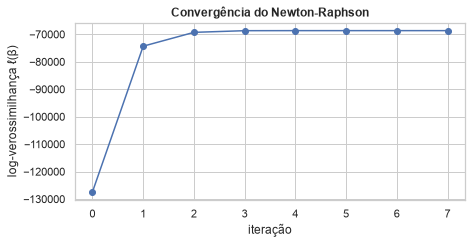

Convergiu em 8 iterações; ℓ(β̂) = -68,634.5


Maior diferença para o scikit-learn: 1.8e-15


In [21]:
from sklearn.linear_model import LogisticRegression


def ajustar_logistica(
    X: pd.DataFrame, y: pd.Series, tol: float = 1e-10, max_iter: int = 50
) -> dict:
    # Regressão logística por máxima verossimilhança (Newton-Raphson / IRLS).
    A = np.column_stack([np.ones(len(X)), X.to_numpy(float)])
    y_arr = y.to_numpy(float)
    beta = np.zeros(A.shape[1])
    historico = []
    for _ in range(max_iter):
        p = 1 / (1 + np.exp(-A @ beta))
        historico.append(np.sum(y_arr * np.log(p) + (1 - y_arr) * np.log(1 - p)))
        informacao = A.T @ (A * (p * (1 - p))[:, None])  # XᵀWX
        passo = np.linalg.solve(informacao, A.T @ (y_arr - p))
        beta += passo
        if np.abs(passo).max() < tol:
            break
    p = 1 / (1 + np.exp(-A @ beta))
    informacao = A.T @ (A * (p * (1 - p))[:, None])
    return {
        "beta": pd.Series(beta, index=["Intercepto", *X.columns]),
        "covariancia": np.linalg.inv(informacao),
        "loglik": np.sum(y_arr * np.log(p) + (1 - y_arr) * np.log(1 - p)),
        "historico": historico,
        "n": len(X),
    }


completo = ajustar_logistica(X, y)

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.plot(range(len(completo["historico"])), completo["historico"], marker="o", color="#4C72B0")
ax.set(xlabel="iteração", ylabel="log-verossimilhança ℓ(β)", title="Convergência do Newton-Raphson")
plt.show()
print(f"Convergiu em {len(completo['historico'])} iterações; ℓ(β̂) = {completo['loglik']:,.1f}")

# Conferência com o scikit-learn sem regularização (C = ∞).
sk = LogisticRegression(C=np.inf, solver="newton-cholesky", tol=1e-10, max_iter=1_000).fit(X, y)
dif = np.abs(np.r_[sk.intercept_, sk.coef_[0]] - completo["beta"].to_numpy()).max()
print(f"Maior diferença para o scikit-learn: {dif:.1e}")

### 6.5 Inferência sobre os coeficientes

Com a matriz de covariância $\widehat{\operatorname{Cov}}(\hat\beta) = (X^\top W X)^{-1}$:

| Quantidade | Fórmula |
|---|---|
| Erro padrão | $\operatorname{EP}(\hat\beta_j) = \sqrt{[(X^\top W X)^{-1}]_{jj}}$ |
| Teste de Wald ($H_0: \beta_j = 0$) | $z = \hat\beta_j / \operatorname{EP}(\hat\beta_j) \sim N(0,1)$ |
| IC 95% do coeficiente | $\hat\beta_j \pm 1{,}96\,\operatorname{EP}(\hat\beta_j)$ |
| Razão de chances e seu IC | $e^{\hat\beta_j}$ e $e^{\hat\beta_j \pm 1{,}96\,\operatorname{EP}}$ |

> As OR estão **na unidade de cada variável**: por ponto de IMC, por faixa etária
> (5 anos), por nível de renda, por dia de saúde ruim e "sim × não" nas binárias.

In [22]:
def tabela_coeficientes(ajuste: dict) -> pd.DataFrame:
    beta = ajuste["beta"]
    ep = pd.Series(np.sqrt(np.diag(ajuste["covariancia"])), index=beta.index)
    z = beta / ep
    return pd.DataFrame(
        {
            "β": beta,
            "EP": ep,
            "z (Wald)": z,
            "p-valor": 2 * stats.norm.sf(z.abs()),
            "IC 95% β (inf)": beta - 1.96 * ep,
            "IC 95% β (sup)": beta + 1.96 * ep,
            "OR": np.exp(beta),
            "OR (inf)": np.exp(beta - 1.96 * ep),
            "OR (sup)": np.exp(beta + 1.96 * ep),
        }
    )


coeficientes = tabela_coeficientes(completo)
coeficientes.rename(index=DESCRICAO).style.format(
    {"p-valor": "{:.1e}", "OR": "{:.3f}", "OR (inf)": "{:.3f}", "OR (sup)": "{:.3f}"}, precision=4
).background_gradient(subset=["z (Wald)"], cmap="RdBu_r", vmin=-60, vmax=60)

,β,EP,z (Wald),p-valor,IC 95% β (inf),IC 95% β (sup),OR,OR (inf),OR (sup)
Intercepto,-7.4500,0.0963,-77.3297,0.0e+00,-7.6389,-7.2612,0.001,0.000,0.001
Pressão alta,0.6854,0.0156,44.0416,0.0e+00,0.6549,0.7159,1.984,1.925,2.046
Colesterol alto,0.5743,0.0145,39.6746,0.0e+00,0.5460,0.6027,1.776,1.726,1.827
Checou colesterol,1.2130,0.0688,17.6347,1.3e-69,1.0782,1.3479,3.364,2.939,3.849
Fumante,-0.0306,0.0141,-2.1627,3.1e-02,-0.0583,-0.0029,0.970,0.943,0.997
Já teve AVC,0.1026,0.0273,3.7549,1.7e-04,0.0490,0.1561,1.108,1.050,1.169
Doença cardíaca,0.1954,0.0193,10.1316,4.0e-24,0.1576,0.2332,1.216,1.171,1.263
Atividade física,-0.0337,0.0154,-2.1876,2.9e-02,-0.0638,-0.0035,0.967,0.938,0.997
Come frutas,-0.0342,0.0146,-2.3363,1.9e-02,-0.0628,-0.0055,0.966,0.939,0.995
Come vegetais,0.0003,0.0170,0.0182,9.9e-01,-0.0330,0.0336,1.000,0.968,1.034


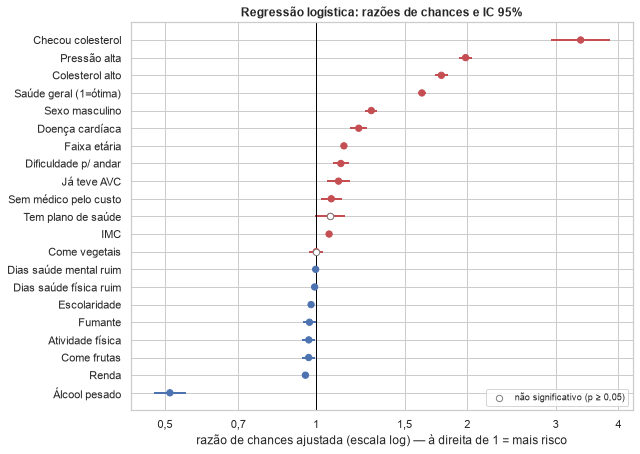

In [23]:
forest = coeficientes.drop(index="Intercepto").sort_values("OR")
nao_sig = forest["p-valor"] >= 0.05

fig, ax = plt.subplots(figsize=(9, 7))
posicoes = np.arange(len(forest))
cores = np.where(forest["OR"] > 1, "#C44E52", "#4C72B0")
ax.hlines(posicoes, forest["OR (inf)"], forest["OR (sup)"], color=cores, lw=2)
ax.scatter(forest["OR"], posicoes, color=cores, s=40, zorder=3)
ax.scatter(
    forest.loc[nao_sig, "OR"],
    posicoes[nao_sig.to_numpy()],
    facecolor="white",
    edgecolor="gray",
    s=40,
    zorder=4,
    label="não significativo (p ≥ 0,05)",
)
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.5, 0.7, 1, 1.5, 2, 3, 4], ["0,5", "0,7", "1", "1,5", "2", "3", "4"])
ax.minorticks_off()
ax.set_yticks(posicoes, forest.index.map(DESCRICAO))
ax.set(
    xlabel="razão de chances ajustada (escala log) — à direita de 1 = mais risco",
    title="Regressão logística: razões de chances e IC 95%",
)
if nao_sig.any():
    ax.legend(loc="lower right", fontsize=9)
plt.show()

### 6.6 Efeito bruto × efeito ajustado

A **OR bruta** vem de uma regressão logística com **uma variável só** (é outra forma
de medir a associação bivariada, como a correlação). A **OR ajustada** vem do modelo
com todas as variáveis. Quando as duas diferem muito, parte do efeito bruto era
**confundimento**: a variável "pegava carona" em outras correlacionadas com ela.

A coluna "mudança (%)" compara os coeficientes na escala log: −50% = o efeito caiu
pela metade; abaixo de −100% = o efeito **inverteu de sinal**.

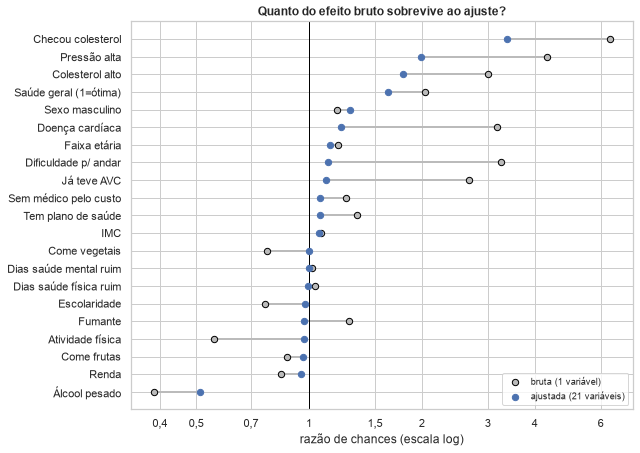

,OR bruta,OR ajustada,mudança (%)
Checou colesterol,6.356,3.364,-34
Pressão alta,4.320,1.984,-53
Colesterol alto,2.996,1.776,-48
Saúde geral (1=ótima),2.036,1.624,-32
Sexo masculino,1.186,1.288,+48
Doença cardíaca,3.166,1.216,-83
Faixa etária,1.196,1.136,-29
Dificuldade p/ andar,3.255,1.120,-90
Já teve AVC,2.670,1.108,-90
Sem médico pelo custo,1.255,1.072,-69


In [24]:
or_bruta = pd.Series({col: np.exp(ajustar_logistica(X[[col]], y)["beta"][col]) for col in features})
bruto_ajustado = pd.DataFrame(
    {"OR bruta": or_bruta, "OR ajustada": coeficientes.loc[features, "OR"]}
)
bruto_ajustado["mudança (%)"] = (
    np.log(bruto_ajustado["OR ajustada"]) / np.log(bruto_ajustado["OR bruta"]) - 1
) * 100
bruto_ajustado = bruto_ajustado.sort_values("OR ajustada")

fig, ax = plt.subplots(figsize=(9, 7))
posicoes = np.arange(len(bruto_ajustado))
ax.hlines(
    posicoes, bruto_ajustado["OR bruta"], bruto_ajustado["OR ajustada"], color="#BBBBBB", lw=2
)
ax.scatter(
    bruto_ajustado["OR bruta"],
    posicoes,
    color="#BBBBBB",
    edgecolor="black",
    s=40,
    zorder=3,
    label="bruta (1 variável)",
)
ax.scatter(
    bruto_ajustado["OR ajustada"],
    posicoes,
    color="#4C72B0",
    s=40,
    zorder=3,
    label="ajustada (21 variáveis)",
)
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_xticks(
    [0.4, 0.5, 0.7, 1, 1.5, 2, 3, 4, 6], ["0,4", "0,5", "0,7", "1", "1,5", "2", "3", "4", "6"]
)
ax.minorticks_off()
ax.set_yticks(posicoes, bruto_ajustado.index.map(DESCRICAO))
ax.set(xlabel="razão de chances (escala log)", title="Quanto do efeito bruto sobrevive ao ajuste?")
ax.legend(loc="lower right", fontsize=9)
plt.show()

bruto_ajustado.rename(index=DESCRICAO).iloc[::-1].style.format(
    {"OR bruta": "{:.3f}", "OR ajustada": "{:.3f}", "mudança (%)": "{:+.0f}"}
)

### 6.7 Comparando modelos: razão de verossimilhança, AIC, BIC e pseudo-R²

Para testar **um bloco** de variáveis de uma vez ($H_0$: todos os coeficientes do
bloco são zero), comparamos o modelo completo com o modelo **reduzido**, sem o bloco:

$$
\text{LR} = 2\,\big[\ell(\hat\beta_{\text{completo}}) - \ell(\hat\beta_{\text{reduzido}})\big] \;\sim\; \chi^2_{q}
\qquad (q = \text{nº de variáveis removidas})
$$

E medidas de qualidade que **penalizam a complexidade** ($k$ = nº de parâmetros):

| Medida | Fórmula | Leitura |
|---|---|---|
| AIC | $2k - 2\ell$ | menor é melhor; penalidade leve |
| BIC | $k \ln n - 2\ell$ | menor é melhor; penalidade cresce com $n$ |
| pseudo-R² de McFadden | $1 - \ell / \ell_{\text{nulo}}$ | 0 = não melhora o modelo só com intercepto |

Comparamos quatro modelos aninhados: o nulo (só intercepto), o das 5 variáveis com
maior |ρs|, o completo sem as 6 de menor |ρs| e o completo.

In [25]:
por_forca = com_alvo.index.map({v: k for k, v in DESCRICAO.items()})
fracas_rho = list(por_forca[-6:])
modelos = {
    "nulo (só intercepto)": [],
    "5 mais correlacionadas": list(por_forca[:5]),
    "sem as 6 mais fracas": [c for c in features if c not in fracas_rho],
    "completo (21)": features,
}
ll_nulo = len(y) * (y.mean() * np.log(y.mean()) + (1 - y.mean()) * np.log(1 - y.mean()))

linhas = []
for nome, colunas in modelos.items():
    ll = ajustar_logistica(X[colunas], y)["loglik"] if colunas else ll_nulo
    k = len(colunas) + 1
    linhas.append(
        {
            "modelo": nome,
            "parâmetros (k)": k,
            "log-verossimilhança": ll,
            "AIC": 2 * k - 2 * ll,
            "BIC": k * np.log(len(y)) - 2 * ll,
            "pseudo-R² (McFadden)": 1 - ll / ll_nulo,
        }
    )
comparacao_modelos = pd.DataFrame(linhas).set_index("modelo")
display(
    comparacao_modelos.style.format(
        {
            "log-verossimilhança": "{:,.1f}",
            "AIC": "{:,.1f}",
            "BIC": "{:,.1f}",
            "pseudo-R² (McFadden)": "{:.4f}",
        }
    ).highlight_min(subset=["AIC", "BIC"], color="#C6E2C6")
)

lr = 2 * (
    comparacao_modelos.loc["completo (21)", "log-verossimilhança"]
    - comparacao_modelos.loc["sem as 6 mais fracas", "log-verossimilhança"]
)
print("Bloco testado (6 de menor |ρs|):", ", ".join(DESCRICAO[c] for c in fracas_rho))
print(
    f"Teste da razão de verossimilhança: LR = {lr:,.1f}  |  gl = {len(fracas_rho)}  |  p = {stats.chi2.sf(lr, len(fracas_rho)):.1e}"
)

,parâmetros (k),log-verossimilhança,AIC,BIC,pseudo-R² (McFadden)
modelo,,,,,
nulo (só intercepto),1,"-84,541.1","169,084.2","169,094.4",0.0000
5 mais correlacionadas,6,"-70,729.0","141,470.1","141,530.8",0.1634
sem as 6 mais fracas,16,"-68,806.1","137,644.2","137,806.1",0.1861
completo (21),22,"-68,634.5","137,312.9","137,535.6",0.1882


Bloco testado (6 de menor |ρs|): Come vegetais, Sexo masculino, Sem médico pelo custo, Come frutas, Tem plano de saúde, Dias saúde mental ruim
Teste da razão de verossimilhança: LR = 343.2  |  gl = 6  |  p = 4.3e-71


📌 **O que observamos**

- **Regressão linear simples:** as três identidades se confirmam: $\hat\beta_1$ pela
  matriz é igual a $r \cdot s_Y/s_X$, o $R^2$ é igual a $r^2$ e o t da inclinação é o
  mesmo t do teste de correlação. **Correlação e regressão simples são a mesma
  informação em escalas diferentes.**
- **Estimação da logística:** o Newton-Raphson converge em poucas iterações (a
  log-verossimilhança sobe rápido e estabiliza) e as estimativas coincidem com as
  do scikit-learn.
- **Coeficientes:** mantendo as demais constantes, **checou colesterol** multiplica a
  chance por 3,4, **pressão alta** por 2,0, **colesterol alto** por 1,8 e cada nível
  pior de **saúde geral** por 1,6. IMC (1,061 por ponto) e idade (1,14 por faixa)
  parecem pequenos, mas acumulam: de IMC 20 a 40 a chance é multiplicada por
  1,061²⁰ ≈ 3,3, e da 1ª à 13ª faixa etária por ≈ 4,6. **Álcool pesado** reduz a
  chance à metade (OR 0,51), um caso de causalidade reversa (notebook 01).
- **Não significativas no modelo ajustado:** come vegetais (p = 0,99) e tem plano de
  saúde (p = 0,06), embora ambas sejam "significativas" sozinhas (seção 4).
- **Bruto × ajustado:** quase todas as OR se aproximam de 1 após o ajuste, pois parte
  do efeito bruto era compartilhado com variáveis correlacionadas (seção 7):
  - **dificuldade de andar** (3,3 → 1,1), **AVC** (2,7 → 1,1) e **doença cardíaca**
    (3,2 → 1,2) perdem ~90% do efeito: elas "carregavam" a saúde geral, a idade e a
    pressão alta;
  - **fumante** (1,28 → 0,97) e **dias de saúde física ruim** (1,04 → 0,99)
    **invertem de sinal**, o mesmo fenômeno visto no Lasso (seção 8.3);
  - **sexo masculino** é o único que **cresce** (1,19 → 1,29): ajustar pelas outras
    variáveis revela um efeito que estava mascarado.
- **Comparação de modelos:** o teste da razão de verossimilhança **rejeita** a
  remoção das 6 variáveis mais fracas, e AIC e BIC preferem o modelo completo. Mas o
  pseudo-R² mal se move entre "sem as 6 mais fracas" e "completo". É a mesma lição
  da seção 4: com 184 mil pessoas, **diferenças pequenas são detectáveis**; o que
  decide se valem a pena é o ganho preditivo (seção 9).

## 7. Redundância e multicolinearidade

Duas variáveis muito correlacionadas entre si carregam **informação repetida**.
Isso é um problema diferente de "pouco relacionada com o alvo":

- para **modelos lineares**, a redundância deixa os coeficientes instáveis e
  difíceis de interpretar;
- para **árvores** (o modelo usado), é praticamente inofensiva: a árvore usa uma
  das duas e ignora a outra.

### 7.1 Pares mais correlacionados

In [26]:
pares = (
    corr_feat.where(~np.triu(np.ones_like(corr_feat, dtype=bool)))
    .stack()
    .rename("spearman")
    .reset_index()
)
pares.columns = ["variável A", "variável B", "spearman"]
pares = pares.reindex(pares["spearman"].abs().sort_values(ascending=False).index).head(10)
pares[["variável A", "variável B"]] = pares[["variável A", "variável B"]].replace(DESCRICAO)
pares.reset_index(drop=True).style.format({"spearman": "{:+.3f}"})

,variável A,variável B,spearman
0,Dias saúde física ruim,Saúde geral (1=ótima),+0.439
1,Saúde geral (1=ótima),Dificuldade p/ andar,+0.420
2,Renda,Escolaridade,+0.417
3,Dias saúde física ruim,Dificuldade p/ andar,+0.404
4,Faixa etária,Pressão alta,+0.336
5,Renda,Saúde geral (1=ótima),-0.314
6,Renda,Dificuldade p/ andar,-0.286
7,Colesterol alto,Pressão alta,+0.285
8,Dias saúde física ruim,Dias saúde mental ruim,+0.283
9,Saúde geral (1=ótima),Pressão alta,+0.275


### 7.2 VIF (fator de inflação da variância)

A correlação olha **pares**. Mas uma variável pode ser redundante com uma
**combinação** de outras. O VIF capta isso: para cada variável $j$, fazemos uma
regressão dela contra todas as outras e medimos o $R^2_j$:

$$
\text{VIF}_j = \frac{1}{1 - R^2_j}
$$

| VIF | Leitura |
|---|---|
| 1 | nenhuma redundância |
| 1–5 | moderada (normal) |
| 5–10 | alta |
| > 10 ou ∞ | a variável é (quase) uma combinação exata das outras |

Calculamos o VIF de duas formas: pela regressão (definição) e pelo atalho
matricial $\text{VIF}_j = [R^{-1}]_{jj}$, a diagonal da **inversa da matriz de correlação**.

In [27]:
from sklearn.linear_model import LinearRegression


def vif(dados: pd.DataFrame) -> pd.Series:
    # VIF pela definição: regride cada coluna contra as demais.
    resultado = {}
    for col in dados.columns:
        outras = dados.drop(columns=col)
        r2 = LinearRegression().fit(outras, dados[col]).score(outras, dados[col])
        resultado[col] = np.inf if r2 > 1 - 1e-9 else 1 / (1 - r2)
    return pd.Series(resultado)


vif_regressao = vif(X)
vif_matriz = pd.Series(np.diag(np.linalg.inv(X.corr().to_numpy())), index=features)

tabela_vif = pd.DataFrame({"VIF (regressão)": vif_regressao, "VIF (diag. de R⁻¹)": vif_matriz})
tabela_vif.rename(index=DESCRICAO).sort_values("VIF (regressão)", ascending=False).style.format(
    "{:.2f}"
).bar(subset=["VIF (regressão)"], color="#DD8452", vmin=0, vmax=5)

,VIF (regressão),VIF (diag. de R⁻¹)
Saúde geral (1=ótima),1.72,1.72
Dias saúde física ruim,1.60,1.60
Dificuldade p/ andar,1.51,1.51
Renda,1.43,1.43
Faixa etária,1.35,1.35
Pressão alta,1.30,1.30
Escolaridade,1.27,1.27
Dias saúde mental ruim,1.22,1.22
Doença cardíaca,1.17,1.17
Colesterol alto,1.16,1.16


### 7.3 E com as variáveis criadas pelo pipeline?

O `ClinicalFeatureEngineer` acrescenta três features derivadas. Duas delas são
**somas exatas** de colunas originais:

- `ComorbidityCount` = pressão alta + colesterol + AVC + doença cardíaca + dificuldade de andar
- `LifestyleScore` = atividade física + frutas + vegetais − fumo − álcool

Recalculamos o VIF com elas:

In [28]:
X_eng = ClinicalFeatureEngineer().fit_transform(X)
vif_eng = vif(X_eng).rename(index=DESCRICAO).sort_values(ascending=False)
vif_eng.to_frame("VIF").head(14).style.format("{:.2f}")

,VIF
Pressão alta,inf
Colesterol alto,inf
Fumante,inf
Já teve AVC,inf
Atividade física,inf
Doença cardíaca,inf
Come frutas,inf
Come vegetais,inf
Nº de comorbidades,inf
Álcool pesado,inf


📌 **O que observamos**

- As duas formas de calcular o VIF dão o mesmo resultado (a fórmula matricial é
  só um atalho).
- **Nas 21 variáveis originais o VIF é baixo**: o maior é 1,7 (saúde geral), longe
  do limite de 5. Os pares mais correlacionados (saúde geral × dias de saúde física
  ruim × dificuldade de andar, renda × escolaridade) têm ρ ≈ 0,40–0,44: redundância
  **moderada**, não grave. **Nenhuma variável precisou ser
  removida por multicolinearidade.**
- **Com as features derivadas, o VIF vai a infinito**: `ComorbidityCount` e
  `LifestyleScore` são combinações lineares exatas das originais, e por isso suas
  componentes também ficam com VIF infinito. O IMC sobe para 2,7 por causa da
  `BMICategory` (o IMC em faixas). Num modelo linear isso tornaria a matriz singular. No
  `HistGradientBoosting` não é problema: a soma pronta apenas oferece à árvore
  um "atalho" que ela levaria vários cortes para montar sozinha. Se o modelo
  linear do registro (`logistic_regression`) fosse escolhido, seria preciso usar
  regularização (o `C` padrão já aplica L2) ou remover as componentes.

## 8. Seleção de variáveis

Existem três famílias de métodos:

| Família | Como funciona | Vantagem | Limitação |
|---|---|---|---|
| **Filtro** | mede cada variável isoladamente contra o alvo (correlação, χ², F, informação mútua) | rápido, independe do modelo | ignora interações e redundância |
| **Embutido** | o próprio modelo zera variáveis inúteis durante o treino (ex.: regressão L1/Lasso) | considera todas juntas | depende do tipo de modelo (aqui, linear) |
| **Wrapper / modelo** | treina o modelo com e sem a variável e mede a diferença (importância por permutação, seleção para frente/trás) | mede o efeito real no modelo final | mais caro |

Usamos as três e comparamos os rankings. A amostra estratificada de 60 mil
linhas abaixo acelera os métodos mais caros sem mudar as conclusões.

In [29]:
amostra = train.groupby(BINARY_TARGET, group_keys=False).sample(
    frac=60_000 / len(train), random_state=SEED
)
Xa, ya = amostra[features], amostra[BINARY_TARGET]
print(f"Amostra: {len(amostra):,} linhas | prevalência {ya.mean():.1%} (treino: {y.mean():.1%})")

Amostra: 60,000 linhas | prevalência 17.3% (treino: 17.3%)


### 8.1 Filtro 1: variáveis quase constantes

Uma variável em que quase todos respondem a mesma coisa tem pouca variância e,
em geral, pouca informação. Medimos a **% da resposta mais comum**.

In [30]:
dominante = (
    pd.DataFrame(
        {
            "resposta mais comum": X.mode().iloc[0],
            "% da resposta mais comum": X.apply(lambda s: s.value_counts(normalize=True).iloc[0]),
            "variância": X.var(),
            "|spearman| com alvo": spearman.loc[features, BINARY_TARGET].abs(),
        }
    )
    .rename(index=DESCRICAO)
    .sort_values("% da resposta mais comum", ascending=False)
)
dominante.head(8).style.format(
    {
        "% da resposta mais comum": "{:.1%}",
        "variância": "{:.3f}",
        "|spearman| com alvo": "{:.3f}",
        "resposta mais comum": "{:.0f}",
    }
)

,resposta mais comum,% da resposta mais comum,variância,|spearman| com alvo
Checou colesterol,1,96.0%,0.038,0.075
Já teve AVC,0,95.5%,0.043,0.098
Tem plano de saúde,1,94.6%,0.051,0.023
Álcool pesado,0,93.9%,0.057,0.064
Sem médico pelo custo,0,90.8%,0.084,0.026
Doença cardíaca,0,89.6%,0.093,0.169
Dificuldade p/ andar,0,81.4%,0.152,0.208
Come vegetais,1,79.5%,0.163,0.041


Um corte usual (ex.: `VarianceThreshold`) seria remover variáveis com mais de 95%
de respostas iguais. Isso eliminaria **checou colesterol** e **já teve AVC**, mas
repare na última coluna: o AVC é raro (4,5%) e ainda assim tem |ρ| = 0,098 com o
alvo, mais que o dobro de variáveis frequentes como fumo ou vegetais (≈ 0,04). **Pouca variância não é sinônimo de pouca
informação**, por isso esse filtro não foi aplicado como corte automático.

### 8.2 Filtro 2: testes estatísticos e informação mútua

Três medidas do `sklearn.feature_selection`, cada uma vê a relação de um ângulo:

- **χ² (`chi2`)**: compara a contagem observada de cada categoria entre doentes e
  saudáveis com a esperada se não houvesse relação. Exige valores não negativos.
- **ANOVA F (`f_classif`)**: compara a **média** da variável entre os dois grupos do
  alvo, relativa à variação dentro de cada grupo.
- **Informação mútua (`mutual_info_classif`)**: quanto saber a variável **reduz a
  incerteza** sobre o alvo. Capta qualquer forma de relação (não só linear/monotônica).

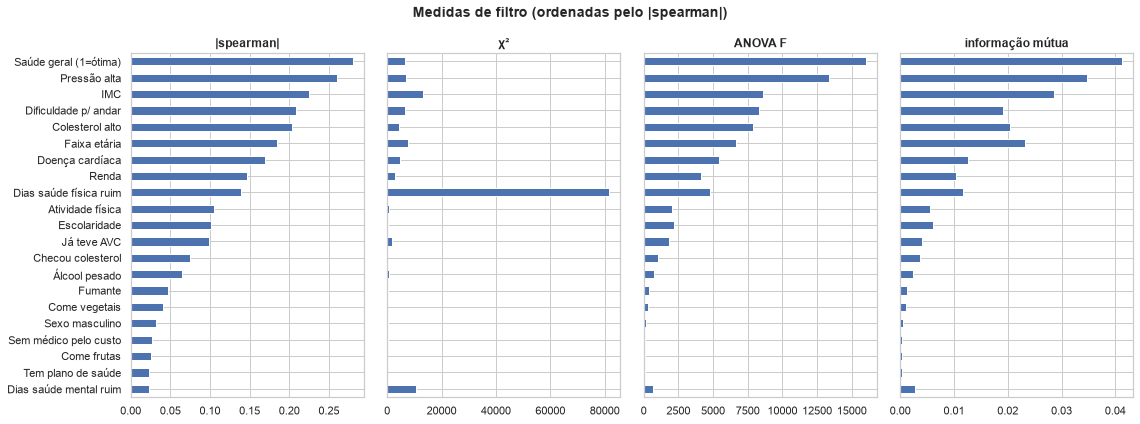

Concordância entre rankings (Spearman entre as colunas):


,|spearman|,χ²,ANOVA F,informação mútua
|spearman|,1.00,0.65,0.97,0.95
χ²,0.65,1.00,0.77,0.78
ANOVA F,0.97,0.77,1.00,0.99
informação mútua,0.95,0.78,0.99,1.00


In [31]:
from sklearn.feature_selection import chi2, f_classif, mutual_info_classif

chi2_stat, _ = chi2(X, y)
f_stat, _ = f_classif(X, y)
mi = mutual_info_classif(
    Xa, ya, discrete_features=[c not in NUMERIC_FEATURES for c in features], random_state=SEED
)

filtros = pd.DataFrame(
    {
        "|spearman|": spearman.loc[features, BINARY_TARGET].abs(),
        "χ²": chi2_stat,
        "ANOVA F": f_stat,
        "informação mútua": mi,
    },
    index=features,
)

fig, axes = plt.subplots(1, 4, figsize=(16, 6), sharey=True)
ordem_filtro = filtros.sort_values("|spearman|").index
for ax, medida in zip(axes, filtros.columns, strict=True):
    filtros.loc[ordem_filtro, medida].rename(index=DESCRICAO).plot.barh(ax=ax, color="#4C72B0")
    ax.set(title=medida, xlabel="")
plt.suptitle("Medidas de filtro (ordenadas pelo |spearman|)", fontweight="bold")
plt.tight_layout()
plt.show()

print("Concordância entre rankings (Spearman entre as colunas):")
filtros.rank(ascending=False).corr(method="spearman").round(2)

### 8.3 Método embutido: regressão logística com penalidade L1 (Lasso)

A penalidade L1 empurra coeficientes **exatamente para zero**. Com regularização
forte (C pequeno), só as variáveis mais úteis sobrevivem; ao relaxar (C maior),
as outras vão entrando. A **ordem de entrada** é um ranking que já considera as
variáveis **juntas** (se duas são redundantes, a segunda tende a entrar tarde).

As variáveis são padronizadas antes, para que os coeficientes sejam comparáveis.

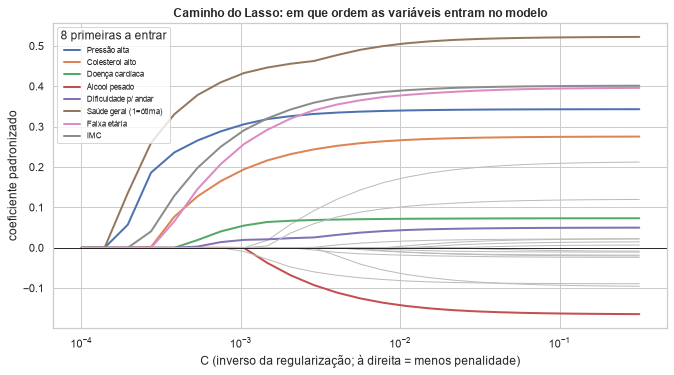

,entra em C =,coef. final (C máx.)
Pressão alta,0.00020,+0.343
Saúde geral (1=ótima),0.00020,+0.522
Colesterol alto,0.00027,+0.275
IMC,0.00027,+0.402
Faixa etária,0.00038,+0.396
Doença cardíaca,0.00054,+0.073
Dificuldade p/ andar,0.00054,+0.050
Álcool pesado,0.00105,-0.164
Renda,0.00105,-0.089
Checou colesterol,0.00147,+0.212


In [32]:
import warnings

from sklearn.exceptions import ConvergenceWarning
from sklearn.preprocessing import StandardScaler

Xa_pad = StandardScaler().fit_transform(Xa)
grade_c = np.logspace(-4, -0.5, 25)
coefs_lasso = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    for C in grade_c:
        modelo = LogisticRegression(
            C=C, l1_ratio=1.0, solver="saga", max_iter=2_000, random_state=SEED
        )
        coefs_lasso.append(modelo.fit(Xa_pad, ya).coef_[0])
caminho = pd.DataFrame(coefs_lasso, index=grade_c, columns=features)

# Primeiro C em que o coeficiente deixa de ser zero = momento em que a variável "entra".
entrada = caminho.ne(0).idxmax().where(caminho.ne(0).any())
ordem_l1 = entrada.sort_values().index

fig, ax = plt.subplots(figsize=(11, 5.5))
destaque = list(ordem_l1[:8])
for col in features:
    ax.plot(
        caminho.index,
        caminho[col],
        lw=2 if col in destaque else 1,
        color=None if col in destaque else "#BBBBBB",
        label=DESCRICAO[col] if col in destaque else None,
    )
ax.set_xscale("log")
ax.axhline(0, color="black", lw=0.8)
ax.set(
    xlabel="C (inverso da regularização; à direita = menos penalidade)",
    ylabel="coeficiente padronizado",
    title="Caminho do Lasso: em que ordem as variáveis entram no modelo",
)
ax.legend(title="8 primeiras a entrar", fontsize=8, loc="upper left")
plt.show()

pd.DataFrame(
    {"entra em C =": entrada[ordem_l1], "coef. final (C máx.)": caminho.iloc[-1][ordem_l1]}
).rename(index=DESCRICAO).style.format(
    {"entra em C =": "{:.5f}", "coef. final (C máx.)": "{:+.3f}"}
)

### 8.4 Wrapper: importância por permutação no modelo real

A etapa `evaluate` do pipeline calcula a **importância por permutação**
([importance.py](../src/diabetes_risk/evaluation/importance.py)): embaralha uma
variável por vez e mede quanto o **PR-AUC** do modelo treinado cai. Se cai muito,
o modelo depende dela; se não cai, ela é dispensável *para este modelo*.

O resultado fica em `reports/feature_importance.csv`. Ele foi medido no teste,
mas só é usado aqui para **interpretar**; a decisão de seleção (seção 9) é tomada
com validação cruzada no treino.

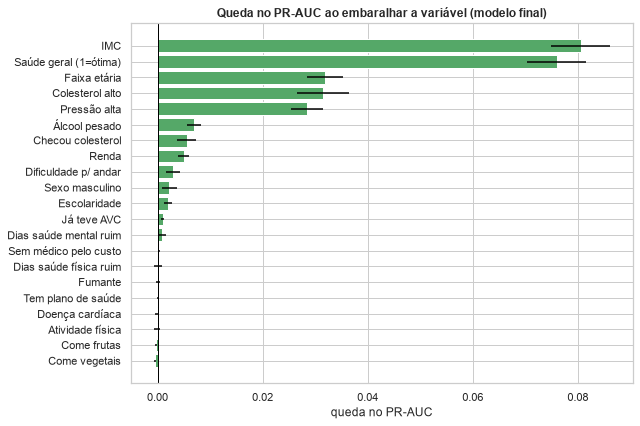

In [33]:
permutacao = pd.read_csv(ROOT / "reports" / "feature_importance.csv", index_col="feature")

fig, ax = plt.subplots(figsize=(9, 6.5))
dados = permutacao.iloc[::-1].rename(index=DESCRICAO)
ax.barh(
    dados.index,
    dados["importance_mean"],
    xerr=dados["importance_std"],
    color="#55A868",
    ecolor="black",
)
ax.axvline(0, color="black", lw=1)
ax.set(title="Queda no PR-AUC ao embaralhar a variável (modelo final)", xlabel="queda no PR-AUC")
plt.show()

### 8.5 Consenso entre os métodos

Convertemos cada medida em **posição no ranking** (1 = mais importante) e tiramos
a média. Uma variável bem colocada em métodos tão diferentes é um sinal robusto.

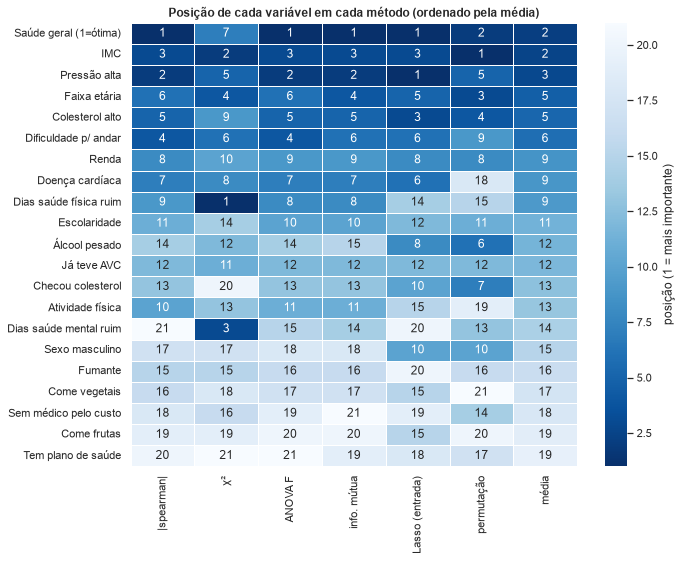

In [34]:
rankings = pd.DataFrame(
    {
        "|spearman|": filtros["|spearman|"].rank(ascending=False),
        "χ²": filtros["χ²"].rank(ascending=False),
        "ANOVA F": filtros["ANOVA F"].rank(ascending=False),
        "info. mútua": filtros["informação mútua"].rank(ascending=False),
        "Lasso (entrada)": entrada.rank(method="min"),
        "permutação": permutacao["importance_mean"].rank(ascending=False),
    }
)
rankings["média"] = rankings.mean(axis=1)
rankings = rankings.sort_values("média")
RANKING_CONSENSO = list(rankings.index)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    rankings.rename(index=DESCRICAO),
    cmap="Blues_r",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "posição (1 = mais importante)"},
    ax=ax,
)
ax.set(title="Posição de cada variável em cada método (ordenado pela média)")
plt.show()

📌 **O que observamos**

- **Os métodos concordam no topo.** Saúde geral, IMC, pressão alta, idade,
  colesterol alto e dificuldade de andar aparecem entre as primeiras em quase
  todos, apesar de medirem coisas diferentes (relação isolada, modelo linear,
  modelo de árvores).
- **Os métodos discordam no meio e no fim**, e as discordâncias são informativas:
  - *Dificuldade de andar*, *dias de saúde física ruim* e *doença cardíaca* vão bem
    nos filtros, mas caem na permutação: são redundantes com a **saúde geral** (e
    entre si); o modelo usa a saúde geral e as outras viram informação repetida.
    No Lasso acontece o mesmo: os dias de saúde física ruim terminam com
    coeficiente **negativo** (−0,10) apesar da correlação positiva com o alvo, porque
    o efeito "positivo" já foi capturado pela saúde geral.
  - O **χ²** é o método que mais discorda dos outros (concordância 0,65): aplicado a
    variáveis numéricas, ele soma os *valores*, e por isso coloca *dias de saúde
    física ruim* em 1º e *saúde mental* em 3º. É o mesmo efeito de escala da
    covariância; o χ² é adequado a contagens/categorias, não a escalas de 0 a 30.
  - *Álcool pesado* e *checou colesterol* são fracos nos filtros, mas aparecem na
    permutação: o modelo de árvores encontra uso para elas **em combinação** com
    outras variáveis.
- No fim do ranking ficam **plano de saúde, frutas, deixar de ir ao médico pelo
  custo, vegetais, fumo e sexo**: candidatas naturais a remoção. A próxima seção testa se removê-las
  de fato ajuda.

## 9. Teste decisivo: menos variáveis pioram o modelo?

Rankings indicam **candidatas**; a decisão vem de um experimento. Treinamos o
mesmo `HistGradientBoosting` do `params.yaml` usando só as **k primeiras
variáveis do ranking de consenso**, para k de 1 a 21, e medimos o PR-AUC com
**validação cruzada estratificada de 5 folds** no treino (a mesma métrica e
estratégia do pipeline).

Isso é uma **seleção para frente** (*forward selection*) guiada pelo ranking.

In [35]:
from sklearn.model_selection import StratifiedKFold, cross_validate

from diabetes_risk.models.registry import build_pipeline, create_classifier

MODELO = PARAMS["model"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
METRICAS = {"PR-AUC": "average_precision", "ROC-AUC": "roc_auc"}


def avaliar(estimador, dados: pd.DataFrame) -> dict[str, float]:
    resultado = cross_validate(estimador, dados, ya, cv=cv, scoring=METRICAS, n_jobs=-1)
    return {
        **{nome: resultado[f"test_{nome}"].mean() for nome in METRICAS},
        "PR-AUC (desvio)": resultado["test_PR-AUC"].std(),
    }


curva = pd.DataFrame(
    {
        k: avaliar(create_classifier(MODELO["name"], MODELO["params"]), Xa[RANKING_CONSENSO[:k]])
        for k in range(1, len(features) + 1)
    }
).T.rename_axis("k")
curva["variável acrescentada"] = [DESCRICAO[c] for c in RANKING_CONSENSO]
curva.style.format(
    {"PR-AUC": "{:.4f}", "ROC-AUC": "{:.4f}", "PR-AUC (desvio)": "{:.4f}"}
).background_gradient(subset=["PR-AUC"], cmap="Greens")

,PR-AUC,ROC-AUC,PR-AUC (desvio),variável acrescentada
k,,,,
1,0.2913,0.7057,0.0048,Saúde geral (1=ótima)
2,0.3651,0.7437,0.0090,IMC
3,0.4019,0.7733,0.0064,Pressão alta
4,0.4245,0.7928,0.0066,Faixa etária
5,0.4366,0.7983,0.0058,Colesterol alto
6,0.4371,0.7989,0.0052,Dificuldade p/ andar
7,0.4399,0.7997,0.0050,Renda
8,0.4433,0.8013,0.0061,Doença cardíaca
9,0.4439,0.8017,0.0068,Dias saúde física ruim


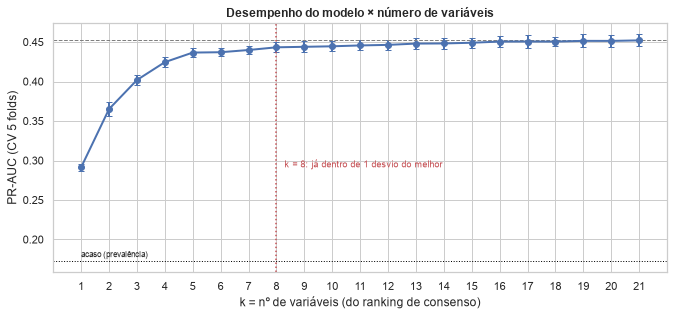

PR-AUC com as 21 variáveis: 0.4521
Melhor PR-AUC:              0.4521 (k = 21)
Com k = 8:                0.4433


In [36]:
melhor = curva["PR-AUC"].max()
# Menor k cujo PR-AUC fica dentro de 1 desvio-padrão do melhor (regra do "1 desvio").
k_suficiente = int(curva.index[curva["PR-AUC"] >= melhor - curva["PR-AUC (desvio)"].max()][0])

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.errorbar(
    curva.index,
    curva["PR-AUC"],
    yerr=curva["PR-AUC (desvio)"],
    marker="o",
    color="#4C72B0",
    capsize=3,
    lw=2,
)
ax.axhline(melhor, ls="--", color="gray", lw=1)
ax.axvline(k_suficiente, ls=":", color="#C44E52", lw=1.5)
ax.annotate(
    f"k = {k_suficiente}: já dentro de 1 desvio do melhor",
    (k_suficiente, curva["PR-AUC"].min()),
    xytext=(8, 0),
    textcoords="offset points",
    color="#C44E52",
    fontsize=9,
)
ax.axhline(ya.mean(), ls=":", color="black", lw=1)
ax.text(1, ya.mean() + 0.005, "acaso (prevalência)", fontsize=8)
ax.set_xticks(curva.index)
ax.set(
    xlabel="k = nº de variáveis (do ranking de consenso)",
    ylabel="PR-AUC (CV 5 folds)",
    title="Desempenho do modelo × número de variáveis",
)
plt.show()

print(f"PR-AUC com as 21 variáveis: {curva['PR-AUC'].iloc[-1]:.4f}")
print(f"Melhor PR-AUC:              {melhor:.4f} (k = {curva['PR-AUC'].idxmax()})")
print(f"Com k = {k_suficiente}:                {curva.loc[k_suficiente, 'PR-AUC']:.4f}")

### 9.1 Teste inverso: remover só as menos importantes

Removemos de uma vez as variáveis do fim do ranking (as "candidatas" da seção 8)
e comparamos com o modelo completo, fold a fold.

In [37]:
candidatas = RANKING_CONSENSO[-6:]  # as 6 últimas do consenso
sem_candidatas = [c for c in features if c not in candidatas]

comparacao_remocao = pd.DataFrame(
    {
        "21 variáveis": avaliar(create_classifier(MODELO["name"], MODELO["params"]), Xa),
        f"{len(sem_candidatas)} variáveis (sem as {len(candidatas)} mais fracas)": avaliar(
            create_classifier(MODELO["name"], MODELO["params"]), Xa[sem_candidatas]
        ),
    }
).T
print("Removidas:", ", ".join(DESCRICAO[c] for c in candidatas))
comparacao_remocao.style.format("{:.4f}")

Removidas: Sexo masculino, Fumante, Come vegetais, Sem médico pelo custo, Come frutas, Tem plano de saúde


,PR-AUC,ROC-AUC,PR-AUC (desvio)
21 variáveis,0.4521,0.8065,0.0077
15 variáveis (sem as 6 mais fracas),0.4491,0.8045,0.0064


📌 **O que observamos**

- A curva **sobe rápido e depois achata**: as primeiras variáveis do consenso
  trazem quase todo o desempenho; as últimas acrescentam muito pouco.
- Com **5 variáveis** (saúde geral, IMC, pressão alta, idade, colesterol) o PR-AUC
  já chega a 0,437; com **8**, a 0,443, dentro de 1 desvio do melhor resultado.
- **Remover variáveis não melhorou o modelo**: o maior PR-AUC (0,452) é justamente
  o das 21 variáveis. Tirar as 6 mais fracas leva a 0,449, diferença bem menor que
  o desvio entre folds (≈ 0,008).
- Ou seja, as variáveis fracas **não atrapalham** (o boosting simplesmente as usa
  pouco) e também **não ajudam muito**.

**Por que então mantê-las?**

1. **Custo zero de coleta:** todas vêm do mesmo questionário; remover não
   economiza nada no uso real.
2. **Sem perda de desempenho** com elas, e possível ganho pequeno em combinações
   (efeito visto no álcool e no "checou colesterol" na seção 8.5).
3. **Menos decisões ajustadas aos dados:** cada corte escolhido olhando métricas é
   um hiperparâmetro a mais, com risco de sobreajuste à amostra.

Se o objetivo mudasse (ex.: um **questionário curto** de triagem), a curva acima
mostra que um modelo com bem menos perguntas perderia pouco. Essa é a principal
utilidade prática desta análise.

## 10. Variáveis criadas (engenharia de features)

O pipeline acrescenta três features ([transformers.py](../src/diabetes_risk/features/transformers.py)):

| Feature | Definição | Motivação clínica |
|---|---|---|
| `ComorbidityCount` | soma de pressão alta, colesterol, AVC, doença cardíaca, dificuldade de andar | o risco **se acumula** com as comorbidades (notebook 01, seção 5.4) |
| `LifestyleScore` | (atividade + frutas + vegetais) − (fumo + álcool) | resume hábitos em um eixo |
| `BMICategory` | faixa de IMC da OMS (0 a 3) | cortes com significado clínico |

### 10.1 Elas se relacionam com o alvo mais do que suas componentes?

In [38]:
X_eng_amostra = ClinicalFeatureEngineer().fit_transform(Xa)
componentes = {
    "ComorbidityCount": ["HighBP", "HighChol", "Stroke", "HeartDiseaseorAttack", "DiffWalk"],
    "LifestyleScore": ["PhysActivity", "Fruits", "Veggies", "Smoker", "HvyAlcoholConsump"],
    "BMICategory": ["BMI"],
}
linhas = []
for derivada, partes in componentes.items():
    rho_partes = {p: stats.spearmanr(Xa[p], ya)[0] for p in partes}
    melhor_parte = max(rho_partes, key=lambda p: abs(rho_partes[p]))
    linhas.append(
        {
            "feature derivada": DESCRICAO[derivada],
            "spearman com alvo": stats.spearmanr(X_eng_amostra[derivada], ya)[0],
            "melhor componente": DESCRICAO[melhor_parte],
            "spearman da componente": rho_partes[melhor_parte],
        }
    )
pd.DataFrame(linhas).set_index("feature derivada").style.format(
    {"spearman com alvo": "{:+.3f}", "spearman da componente": "{:+.3f}"}
)

,spearman com alvo,melhor componente,spearman da componente
feature derivada,,,
Nº de comorbidades,+0.324,Pressão alta,+0.261
Escore de estilo de vida,-0.084,Atividade física,-0.108
Faixa de IMC (OMS),+0.204,IMC,+0.222


### 10.2 Elas melhoram o modelo?

Comparamos, com a mesma validação cruzada, o classificador nas 21 variáveis
originais com o **pipeline completo do projeto** (`build_pipeline`: engenharia +
padronização + classificador).

In [39]:
efeito_engenharia = pd.DataFrame(
    {
        "21 originais": avaliar(create_classifier(MODELO["name"], MODELO["params"]), Xa),
        "21 originais + 3 derivadas (pipeline do projeto)": avaliar(
            build_pipeline(MODELO["name"], MODELO["params"]), Xa
        ),
    }
).T
efeito_engenharia.style.format("{:.4f}")

,PR-AUC,ROC-AUC,PR-AUC (desvio)
21 originais,0.4521,0.8065,0.0077
21 originais + 3 derivadas (pipeline do projeto),0.4508,0.8061,0.0082


📌 **O que observamos**

- `ComorbidityCount` tem **correlação com o alvo maior que qualquer uma das suas
  componentes**: somar as comorbidades concentra o sinal, como o notebook 01 já
  sugeria (o risco cresce a cada fator a mais).
- `LifestyleScore` (−0,08) fica **abaixo** da sua melhor componente, a atividade
  física (−0,11): somar hábitos de pesos diferentes dilui o sinal. E `BMICategory`
  (0,20) perde um pouco em relação ao IMC contínuo (0,22), pois agrupar em faixas
  descarta informação.
- **No desempenho do boosting, as derivadas não trazem ganho mensurável** (PR-AUC
  0,451 contra 0,452, diferença muito menor que o desvio entre folds). Era o
  esperado: as árvores conseguem montar essas somas e cortes sozinhas.
- Elas continuam no pipeline por serem **interpretáveis**, não custarem nada e
  ajudarem caso o modelo seja trocado por um linear (que não monta somas sozinho).
  Para o `HistGradientBoosting`, são candidatas a simplificação: `LifestyleScore`
  e `BMICategory` em especial.

## 11. Conclusões: o que foi decidido

| Etapa | Técnica | Resultado | Decisão |
|---|---|---|---|
| Covariância | fórmula + matriz | sinal útil, magnitude depende da unidade | usada só como base da correlação |
| Correlação | Pearson, Spearman (postos), Kendall (pares) | mesma ordem nos três; Pearson distorcido por assimetria/extremos; τ ≈ ⅔ ρs | **Spearman** como medida principal, Kendall como confirmação |
| Testes de hipótese | t, z de Kendall, permutação, Bonferroni/Holm | todas as 21 rejeitam ρ = 0 (n = 184 mil) | p-valor **não** serve para selecionar aqui |
| Estimação | erro padrão, IC de Fisher e bootstrap | ICs de ±0,005; |ρs| máx. = 0,28 | ranquear por **tamanho do efeito** com IC |
| Modelo estatístico | regressão logística por máxima verossimilhança; Wald, LR, AIC/BIC | efeitos ajustados menores que os brutos; LR/AIC/BIC preferem o modelo completo | confirma o papel das variáveis principais e a decisão de manter todas |
| Redundância | pares de ρ, VIF | originais com VIF ≤ 1,7; derivadas → VIF ∞ | nenhuma remoção (árvores toleram); exige cuidado em modelo linear |
| Quase constantes | % da resposta dominante | 2 variáveis > 95%, mas AVC é informativo | **sem corte automático** |
| Filtros | χ², ANOVA F, informação mútua | concordam no topo; χ² distorcido pela escala | gerar ranking |
| Embutido | Lasso (caminho L1) | ordem de entrada parecida com os filtros | gerar ranking |
| Wrapper | importância por permutação | modelo depende de poucas variáveis; usa álcool/checou colesterol em combinações | gerar ranking |
| **Teste decisivo** | **CV com top-k variáveis** | 8 variáveis já chegam perto; o melhor PR-AUC é com as 21 | **manter as 21 variáveis** |
| Engenharia | 3 features derivadas | `ComorbidityCount` concentra sinal; sem ganho no boosting | **manter** (interpretáveis, úteis para modelos lineares) |

### Variáveis principais

As variáveis que todos os métodos colocam no topo são **saúde geral, IMC,
pressão alta, idade, colesterol alto e dificuldade de andar**. Elas coincidem com
os fatores de risco conhecidos para diabetes tipo 2, o que dá confiança de que o
modelo aprende relações com sentido clínico.

> ⚠️ **Lembrete:** importância e correlação **não são causalidade**. Variáveis como
> "checou colesterol" e "álcool pesado" ajudam a *prever*, mas refletem
> comportamento de quem já tem diagnóstico (causalidade reversa; ver notebook 01,
> seção 5.1). Elas servem para triagem, não para recomendar condutas.